# Rossmann Store Sales

## Učitavanje biblioteka

In [1]:
# Osnovne biblioteke
import warnings
from tqdm import tqdm

import numpy as np
import pandas as pd

# Vizualizacija
import matplotlib.pyplot as plt
import seaborn as sns

# Statistika i analiza vremenskih serija
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Skaliranje i modeli
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
import xgboost as xgb
import optuna

# Postavke
warnings.filterwarnings("ignore")
tqdm.pandas()


c:\Users\lukam\anaconda3\envs\op_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Učitavanje podataka

In [ ]:
store = pd.read_csv("data/store.csv")
data = pd.read_csv("data/train.csv", parse_dates=['Date'], dtype={'StateHoliday': 'str'})

## EDA

### Rossmann Store Sales – opis kolona

| Kolona | Tip | Opis |
|---------|-----|------|
| Store | int | Jedinstveni ID svake prodavnice. |
| DayOfWeek | int | Dan u nedelji (1 = ponedeljak, 7 = nedelja). |
| Date | datetime | Datum posmatranog dana. |
| Sales | float | Iznos dnevne prodaje (ciljna promenljiva za predikciju). |
| Customers | int | Broj kupaca koji su posetili prodavnicu tog dana. |
| Open | int (0/1) | Da li je prodavnica bila otvorena (1 = da, 0 = ne). |
| Promo | int (0/1) | Da li je tog dana bila aktivna promotivna kampanja (1 = da, 0 = ne). |
| StateHoliday | str | Državni praznik: '0' nije praznik, 'a' javni, 'b' verski, 'c' Božić. |
| SchoolHoliday | int (0/1) | Da li su škole bile zatvorene zbog raspusta ili praznika (1 = da, 0 = ne). |


In [3]:
data.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


### Rossmann Store – opis kolona

| Kolona | Tip | Opis |
|--------|-----|------|
| Store | int | Jedinstveni ID svake prodavnice. |
| StoreType | str | Tip prodavnice (A, B, C, D) koji opisuje veličinu i obim prodaje. |
| Assortment | str | Tip asortimana u prodavnici: 'a' = osnovni, 'b' = prošireni, 'c' = kompletan. |
| CompetitionDistance | float | Udaljenost do najbliže konkurentske prodavnice u metrima. |
| CompetitionOpenSinceMonth | float/int | Mesec kada je konkurentska prodavnica otvorena. Može biti NaN ako nije poznato. |
| CompetitionOpenSinceYear | float/int | Godina kada je konkurentska prodavnica otvorena. Može biti NaN ako nije poznato. |
| Promo2 | int (0/1) | Da li prodavnica učestvuje u Promo2 programu (stalne promotivne kampanje). |
| Promo2SinceWeek | float/int | Nedelja kada je prodavnica počela sa Promo2 programom. Može biti NaN. |
| Promo2SinceYear | float/int | Godina kada je prodavnica počela sa Promo2 programom. Može biti NaN. |
| PromoInterval | str | Mesečni intervali u kojima se Promo2 kampanja odvija, npr. "Feb,May,Aug,Nov". Može biti NaN ako nije aktivno. |


In [4]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


### Nedostajući podaci

- Ako **Promo2 = 0**, znači da prodavnica ne učestvuje u Promo2 programu.  
  - U tom slučaju kolone `Promo2SinceWeek` , `Promo2SinceYear` i `PromoInterval` se **popunjavaju nulama**.  

- Ako nemamo podatke o tome kada je konkurentska prodavnica otvorena (`CompetitionOpenSinceMonth` i `CompetitionOpenSinceYear`), te vrednosti se **popunjavaju nulama**.  
  - `CompetitionDistance` se procenjuje srednjom vrednosti poznatih distanci.


In [5]:
print(store.isnull().sum())

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


In [25]:
store['CompetitionDistance'] = store['CompetitionDistance'].fillna(store['CompetitionDistance'].median())
store['CompetitionOpenSinceMonth'] = store['CompetitionOpenSinceMonth'].fillna(1)
store['CompetitionOpenSinceYear'] = store['CompetitionOpenSinceYear'].fillna(2025)

In [26]:
print("Broj prodavnica po Promo2:")
print(store.Promo2.value_counts())
print("\n")

print("Broj NaN vrednosti po kolonama kada ima Promo2:")
print(store[store.Promo2=='0'].isnull().sum())

store = store.fillna(0)


Broj prodavnica po Promo2:
Promo2
1    571
0    544
Name: count, dtype: int64


Broj NaN vrednosti po kolonama kada ima Promo2:
Store                        0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64


### Provera potpune pokrivenosti podataka po prodavnicama

U ovom delu analize proverava se da li svaka prodavnica (`Store`) ima podatke za sve datume u opsegu od najmanjeg do najvećeg datuma.  


In [5]:
total_missing = 0
total_expected = 0

for store_ in data['Store'].unique():
    store_dates = pd.to_datetime(data[data['Store'] == store_]['Date'])
    full_date_range = pd.date_range(start=store_dates.min(), end=store_dates.max())
    
    missing_dates = full_date_range.difference(store_dates)
    
    total_missing += len(missing_dates)
    total_expected += len(full_date_range)

# Ukupni procenat nedostajućih datuma
missing_percentage = (total_missing / total_expected) * 100
print(f"Ukupni procenat nedostajućih datuma: {missing_percentage:.2f}%")


Ukupni procenat nedostajućih datuma: 3.15%


### Analiza nulte prodaje

In [27]:
closed_sales = data[data['Open'] == 0]['Sales']
print("Prodaja kada je prodavnica zatvorena:")
print(closed_sales.value_counts())

# Koliko puta prodaja 0 kada su prodavnice otvorene
open_zero_sales = data[(data['Open'] == 1) & (data['Sales'] == 0)]
print("Broj dana kada je prodaja 0 dok je prodavnica otvorena:", len(open_zero_sales))

# Zadržavanje samo redove gde je vrednost prodaje različita od 0
data = data[data['Sales'] != 0]

# Uklanjanje kolone 'Open' iz DataFrame-a
data = data.drop(columns=['Open'])

Prodaja kada je prodavnica zatvorena:
Sales
0    172817
Name: count, dtype: int64
Broj dana kada je prodaja 0 dok je prodavnica otvorena: 54


### Histogram prodaje

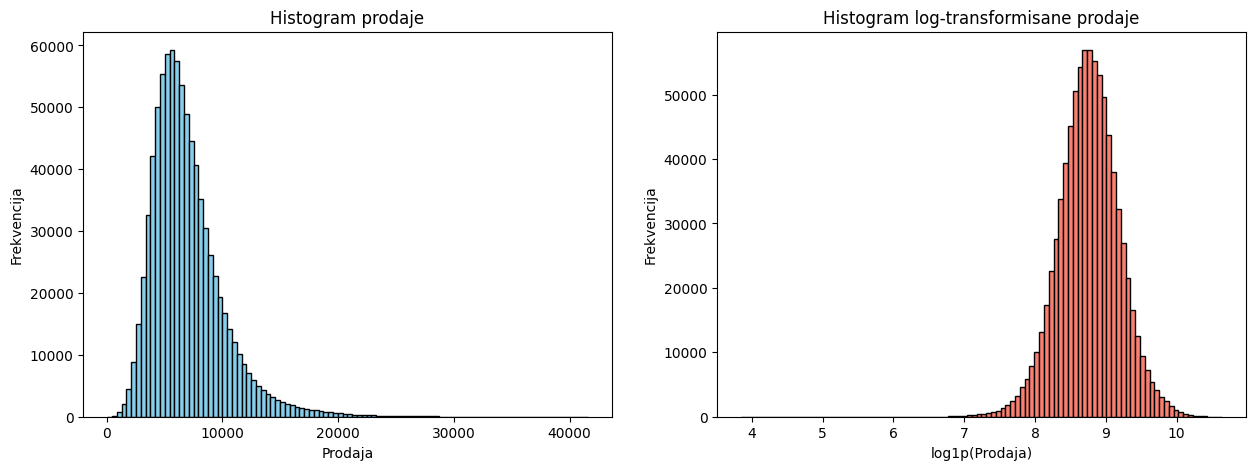

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))  # 1 red, 2 kolone

axes[0].hist(data['Sales'], bins=100, color='skyblue', edgecolor='black')
axes[0].set_title('Histogram prodaje')
axes[0].set_xlabel('Prodaja')
axes[0].set_ylabel('Frekvencija')

axes[1].hist(np.log1p(data['Sales']), bins=100, color='salmon', edgecolor='black')
axes[1].set_title('Histogram log-transformisane prodaje')
axes[1].set_xlabel('log1p(Prodaja)')
axes[1].set_ylabel('Frekvencija')

fig.savefig('latex-izvestaj\grafici\sales_histogram.png', dpi=75)

### Spajanje podataka o prodaji i prodavnicama

In [28]:
data = pd.merge(left = data, right = store, how='left', on = 'Store')

### Prosečna prodaja po tipu prodavnice i promociji po godinama i mesecima

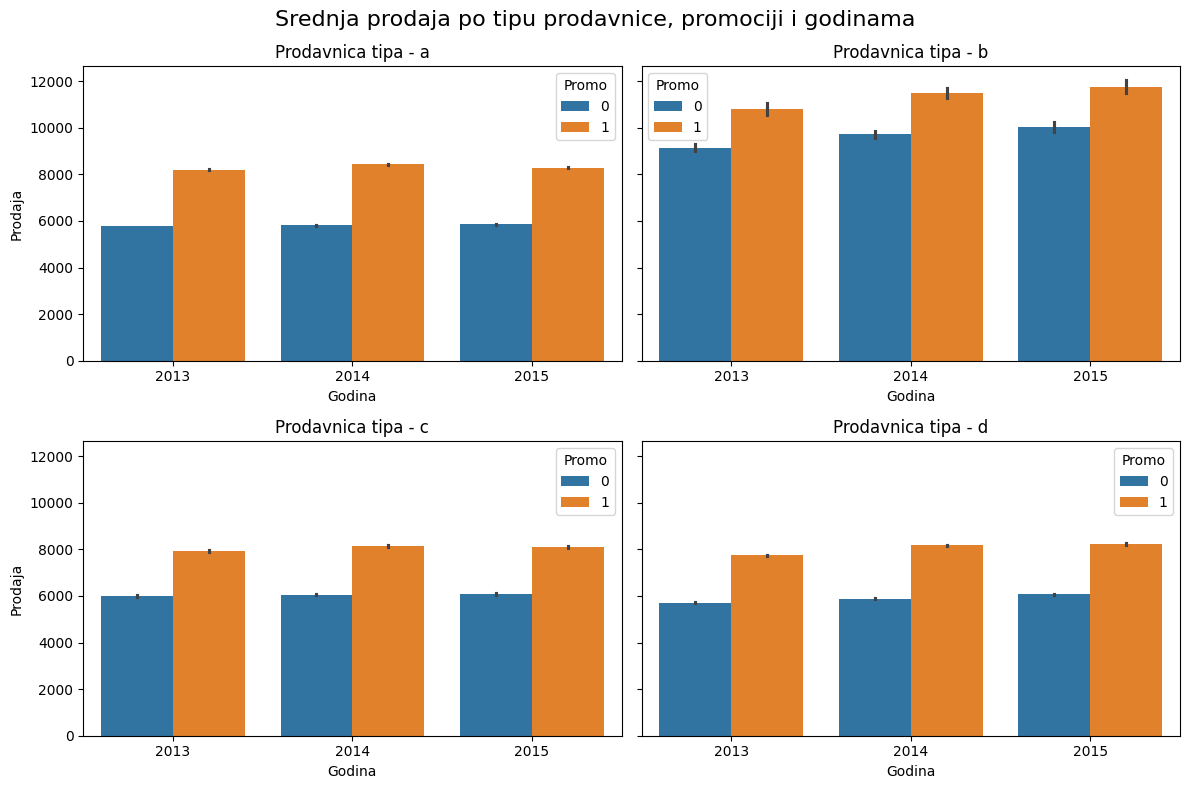

In [29]:
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day

# Lista svih tipova prodavnica
store_types = sorted(data['StoreType'].unique())

fig, axes = plt.subplots(2, 2, figsize=(12, 2*len(store_types)), sharey=True)

for i, store_type in enumerate(store_types):
    df_store = data[data['StoreType'] == store_type]

    sns.barplot(x='Year', y='Sales', data=df_store, ax=axes[i//2][i%2], hue='Promo')
    axes[i//2][i%2].set_title(f'Prodavnica tipa - {store_type}')
    axes[i//2][i%2].set_xlabel('Godina')
    axes[i//2][i%2].set_ylabel('Prodaja')
    
plt.suptitle('Srednja prodaja po tipu prodavnice, promociji i godinama', fontsize=16)
plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\promo_by_year.png', dpi=75)
plt.show()


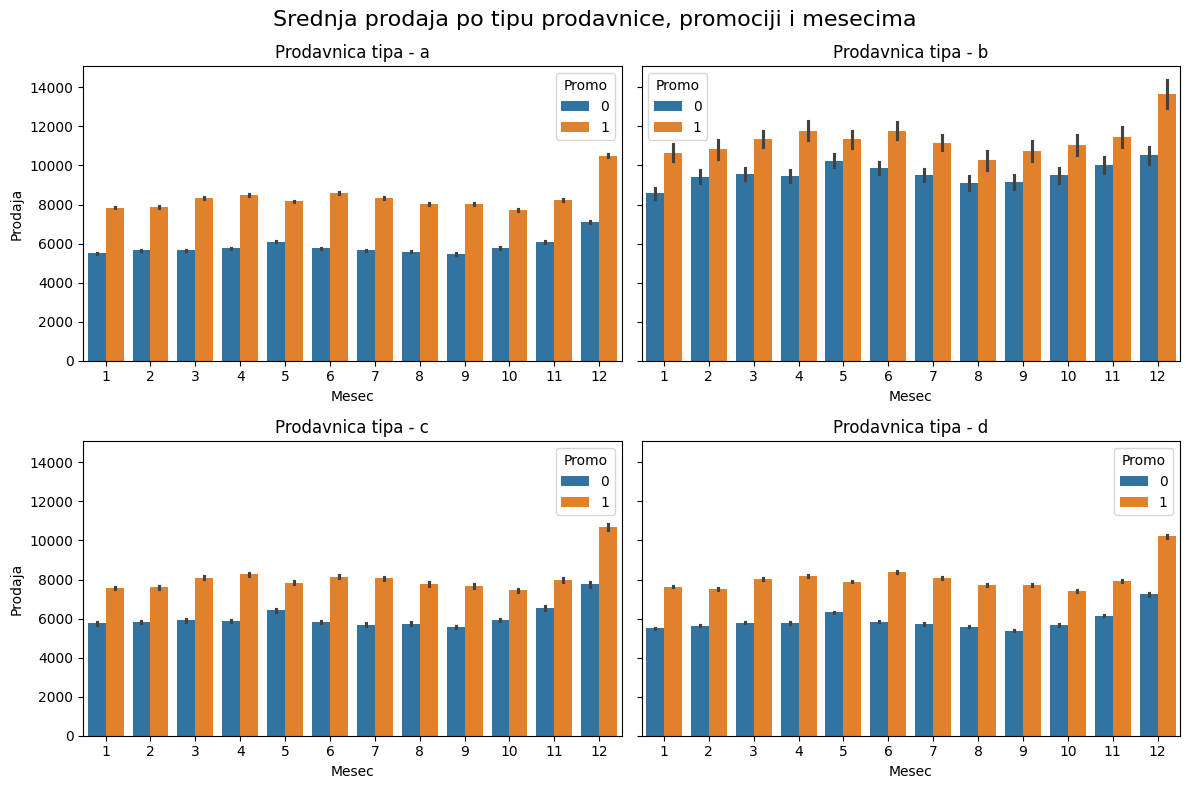

In [13]:
# Lista svih tipova prodavnica
store_types = sorted(data['StoreType'].unique())

# Kreiranje subplot mreže
fig, axes = plt.subplots(2, 2, figsize=(12, 2*len(store_types)), sharey=True)

for i, store_type in enumerate(store_types):
    df_store = data[data['StoreType'] == store_type]
    
    sns.barplot(x='Month', y='Sales', data=df_store, ax=axes[i//2][i%2], hue='Promo')
    axes[i//2][i%2].set_title(f'Prodavnica tipa - {store_type}')
    axes[i//2][i%2].set_xlabel('Mesec')
    axes[i//2][i%2].set_ylabel('Prodaja')

plt.suptitle('Srednja prodaja po tipu prodavnice, promociji i mesecima', fontsize=16)
plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\promo_by_month.png', dpi=75)
plt.show()


### Prosečna prodaja po tipu prodavnice i promociji po danu u nedelji

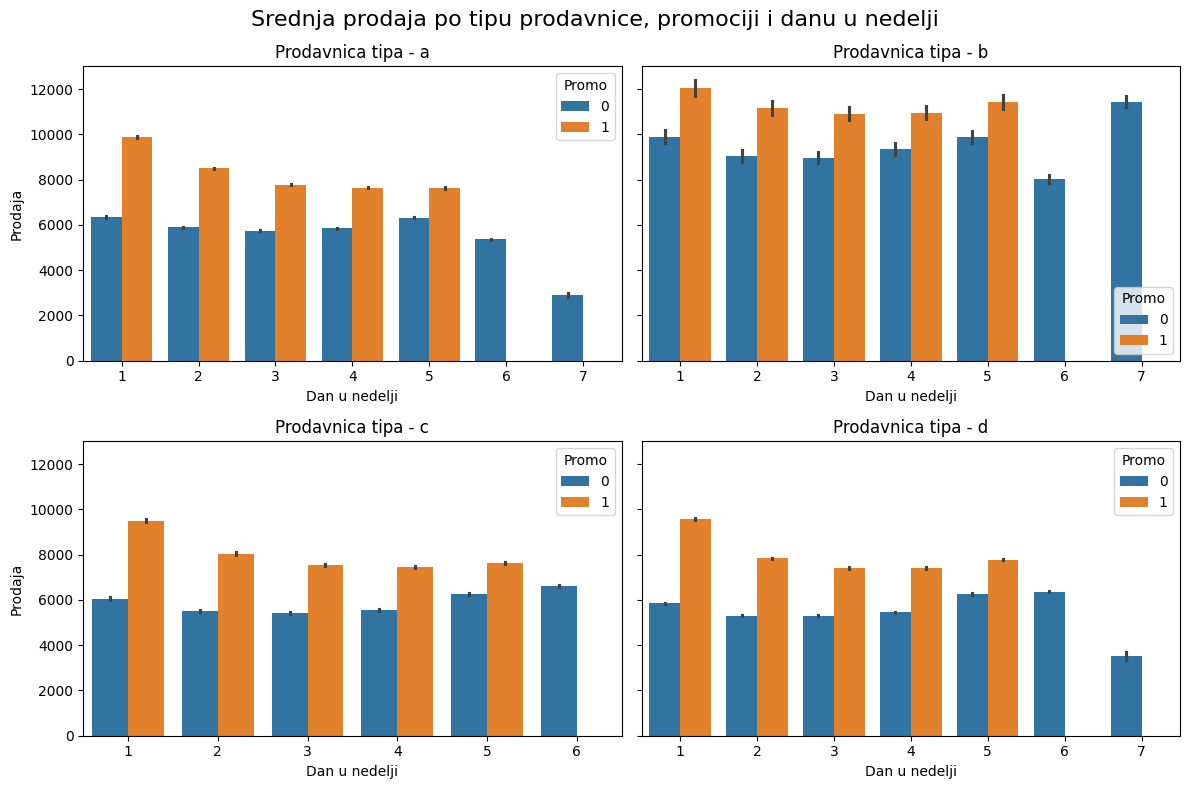

In [14]:
# Lista svih tipova prodavnica
store_types = sorted(data['StoreType'].unique())

fig, axes = plt.subplots(2, 2, figsize=(12, 2*len(store_types)), sharey=True)

for i, store_type in enumerate(store_types):
    df_store = data[data['StoreType'] == store_type]
    
    sns.barplot(x='DayOfWeek', y='Sales', data=df_store, ax=axes[i//2][i%2], hue='Promo')
    axes[i//2][i%2].set_title(f'Prodavnica tipa - {store_type}')
    axes[i//2][i%2].set_xlabel('Dan u nedelji')
    axes[i//2][i%2].set_ylabel('Prodaja')

plt.suptitle('Srednja prodaja po tipu prodavnice, promociji i danu u nedelji', fontsize=16)
plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\promo_by_day.png', dpi=75)
plt.show()

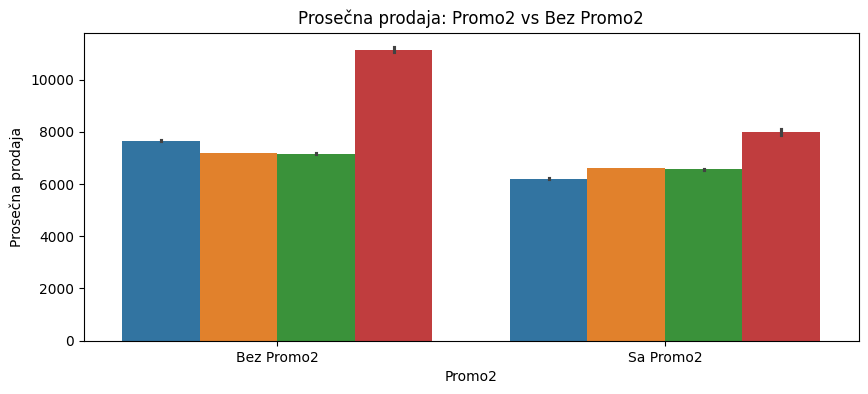

In [15]:
plt.figure(figsize=(10, 4))
sns.barplot(x='Promo2', y='Sales', hue='StoreType', data=data)
plt.legend().remove()
plt.title('Prosečna prodaja: Promo2 vs Bez Promo2')
plt.xlabel('Promo2')
plt.ylabel('Prosečna prodaja')
plt.xticks([0,1], ['Bez Promo2', 'Sa Promo2'])
plt.savefig('latex-izvestaj\grafici\promo2_avg_sales.png', dpi=75)
plt.show()

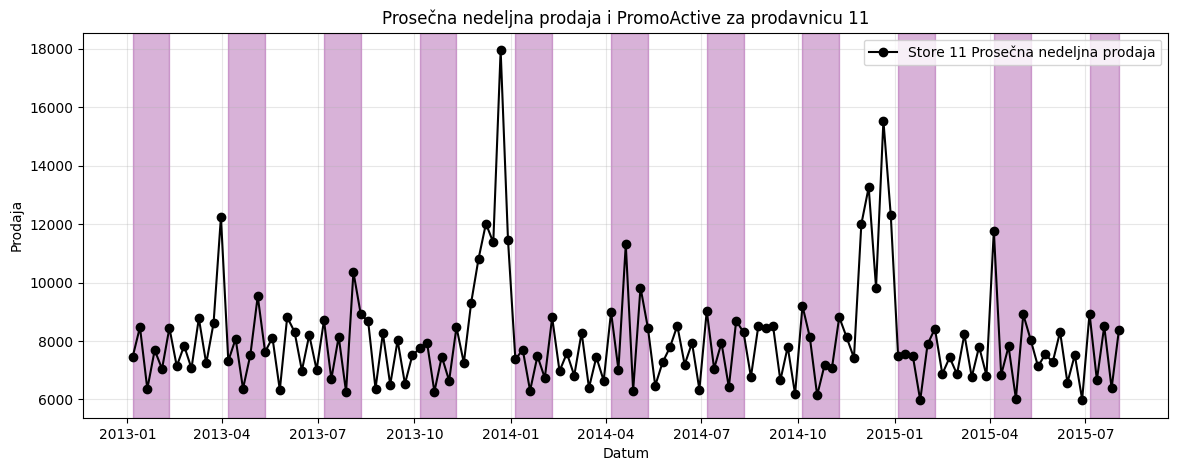

In [16]:
store_id = 11
store_df = data[data['Store'] == store_id].sort_values('Date').copy()

def is_in_promo(row):
    if not isinstance(row['PromoInterval'], str):
        return 0
    month_str = row['Date'].strftime('%b') 
    promo_months = row['PromoInterval'].split(',')
    return 1 if month_str in promo_months else 0

store_df['PromoActive'] = store_df.apply(is_in_promo, axis=1)

store_df.set_index('Date', inplace=True)

# Resample po nedeljama
weekly_sales = store_df['Sales'].resample('W').mean()
weekly_promo = store_df['PromoActive'].resample('W').max()

# Plot prosečne nedeljne prodaje
plt.figure(figsize=(14,5))
plt.plot(weekly_sales.index, weekly_sales.values, color='black', marker='o', label=f'Store {store_id} Prosečna nedeljna prodaja')

# Dodavanje senčenih blokova za nedelje kada je promo aktivan
in_block = False
for date, active in weekly_promo.items():
    if active == 1 and not in_block:
        start_block = date
        in_block = True
    elif active == 0 and in_block:
        end_block = date
        plt.axvspan(start_block, end_block, color='purple', alpha=0.3)
        in_block = False
# Ako poslednji interval ide do kraja
if in_block:
    plt.axvspan(start_block, weekly_promo.index[-1], color='purple', alpha=0.3)

plt.title(f'Prosečna nedeljna prodaja i PromoActive za prodavnicu {store_id}')
plt.xlabel('Datum')
plt.ylabel('Prodaja')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('latex-izvestaj\grafici\promo2_example.png', dpi=75)
plt.show()


### Uticaj dolaska konkurencije na nedeljnu prodaju prodavnica

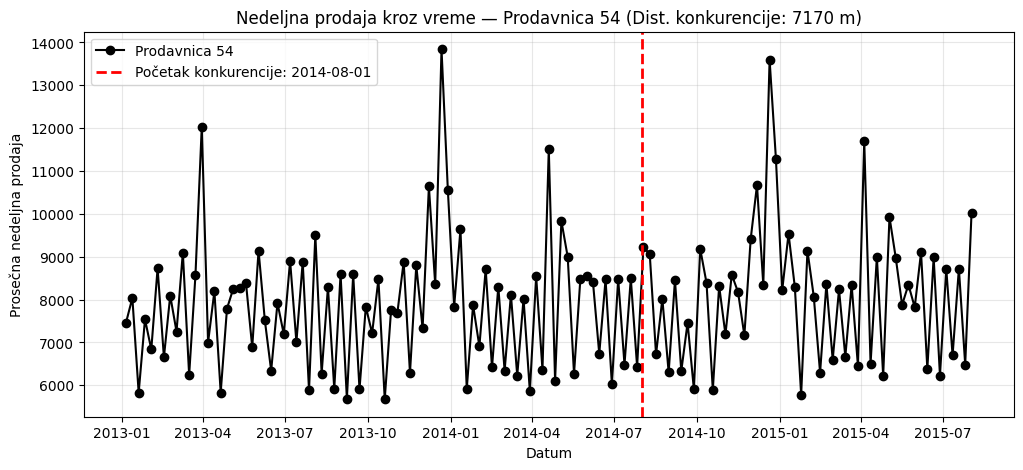

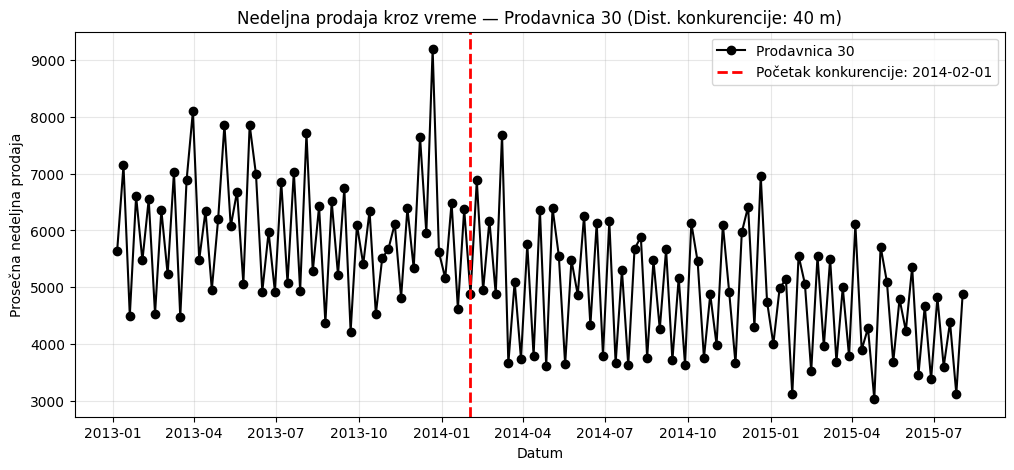

In [17]:
stores_to_plot = [54, 30]
dist = {0:"far", 1:"near"}
for ind, store_id in enumerate(stores_to_plot):
    store_df = data[data['Store'] == store_id].sort_values('Date').copy()

    comp_distance = store_df['CompetitionDistance'].iloc[0]
    comp_distance_label = f"{int(comp_distance)} m"

    store_df.set_index('Date', inplace=True)

    weekly_sales = store_df['Sales'].resample('W').mean()

    # Datum dolaska konkurencije
    year = store_df['CompetitionOpenSinceYear'].iloc[0]
    month = store_df['CompetitionOpenSinceMonth'].iloc[0]

    comp_date = pd.to_datetime(f"{int(year)}-{int(month)}-01")

    plt.figure(figsize=(12,5))
    plt.plot(weekly_sales.index, weekly_sales.values, color='black', marker='o',
             label=f'Prodavnica {store_id}')

    # Linija konkurencije
    if comp_date:
        plt.axvline(comp_date, color='red', linestyle='--', linewidth=2,
                    label=f'Početak konkurencije: {comp_date.date()}')

    plt.title(f'Nedeljna prodaja kroz vreme — Prodavnica {store_id} (Dist. konkurencije: {comp_distance_label})')
    plt.xlabel('Datum')
    plt.ylabel('Prosečna nedeljna prodaja')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(f"latex-izvestaj\grafici\competition_" + dist[ind], dpi=75)
    plt.show()


### Prodaja za vreme državnih praznika

### Prodaja za vreme državnih praznika i školskog raspusta

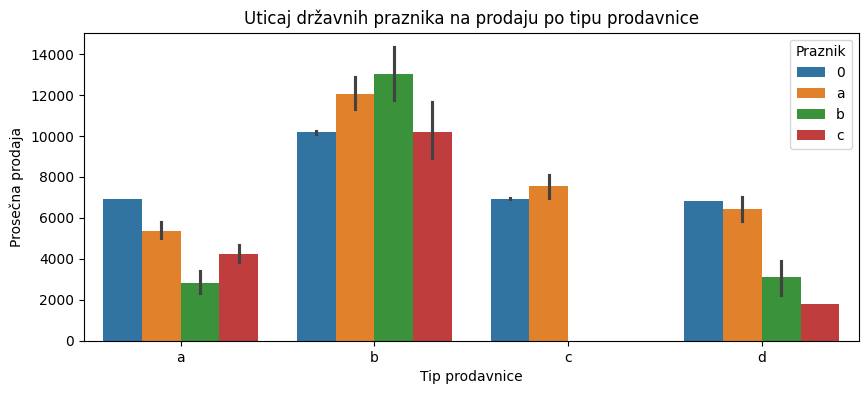

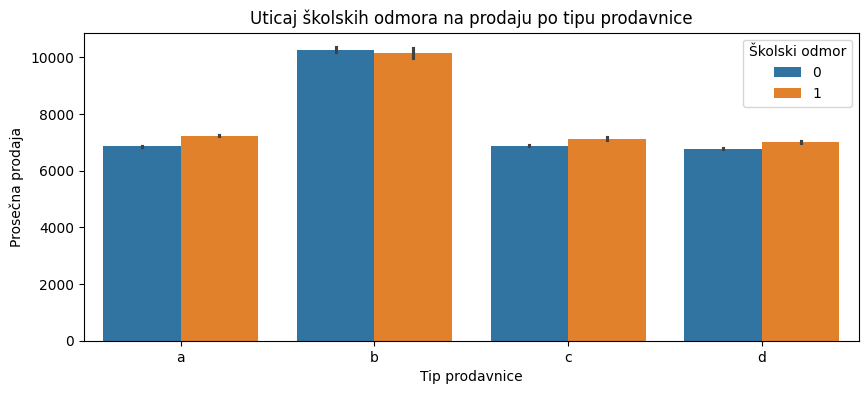

In [18]:
order = sorted(data['StoreType'].unique())

# StateHoliday po StoreType
plt.figure(figsize=(10,4))
sns.barplot(x='StoreType', y='Sales', data=data, hue='StateHoliday', order=order)
plt.title('Uticaj državnih praznika na prodaju po tipu prodavnice')
plt.xlabel('Tip prodavnice')
plt.ylabel('Prosečna prodaja')
plt.legend(title='Praznik')
plt.savefig(f"latex-izvestaj\grafici\holiday_effects.png", dpi=75)
plt.show()

# SchoolHoliday po StoreType
plt.figure(figsize=(10,4))
sns.barplot(x='StoreType', y='Sales', data=data, hue='SchoolHoliday', order=order)
plt.title('Uticaj školskih odmora na prodaju po tipu prodavnice')
plt.xlabel('Tip prodavnice')
plt.ylabel('Prosečna prodaja')
plt.legend(title='Školski odmor')
plt.savefig(f"latex-izvestaj\grafici\school_holidays.png", dpi=75)
plt.show()


### Provera stacionarnosti

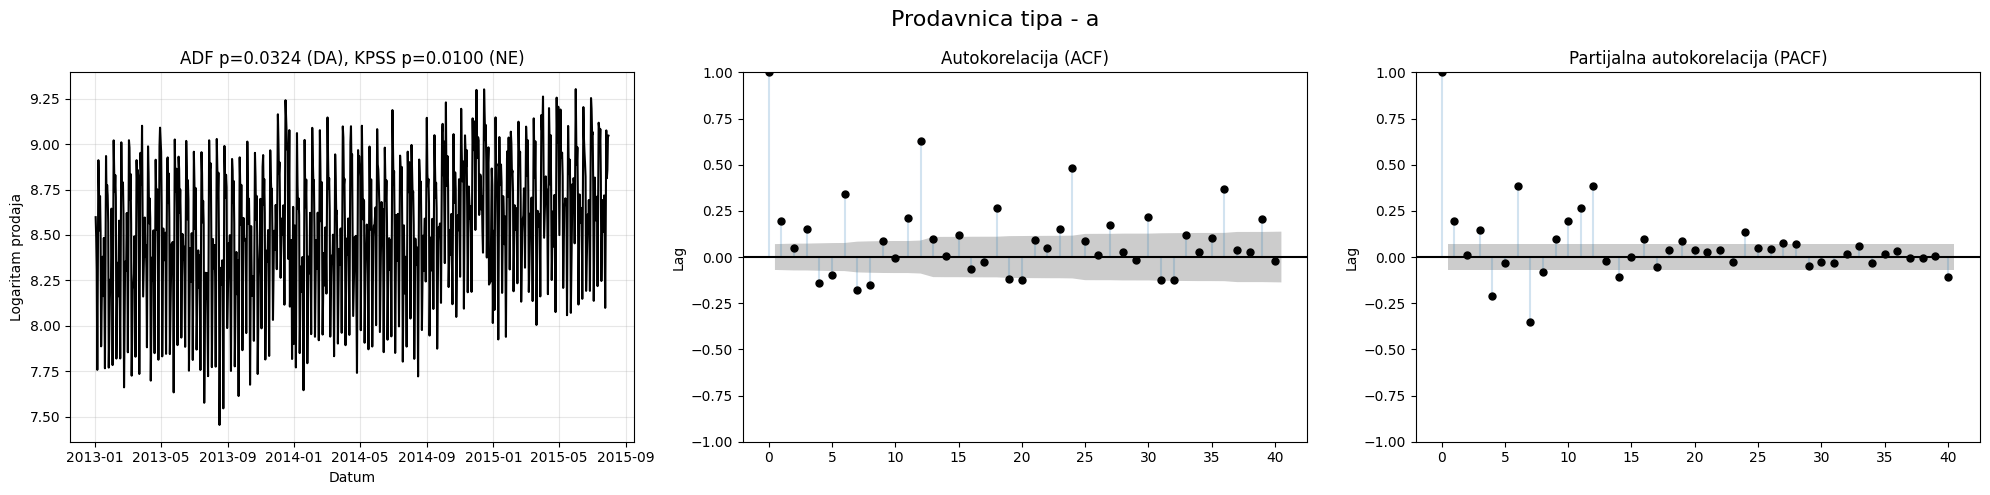

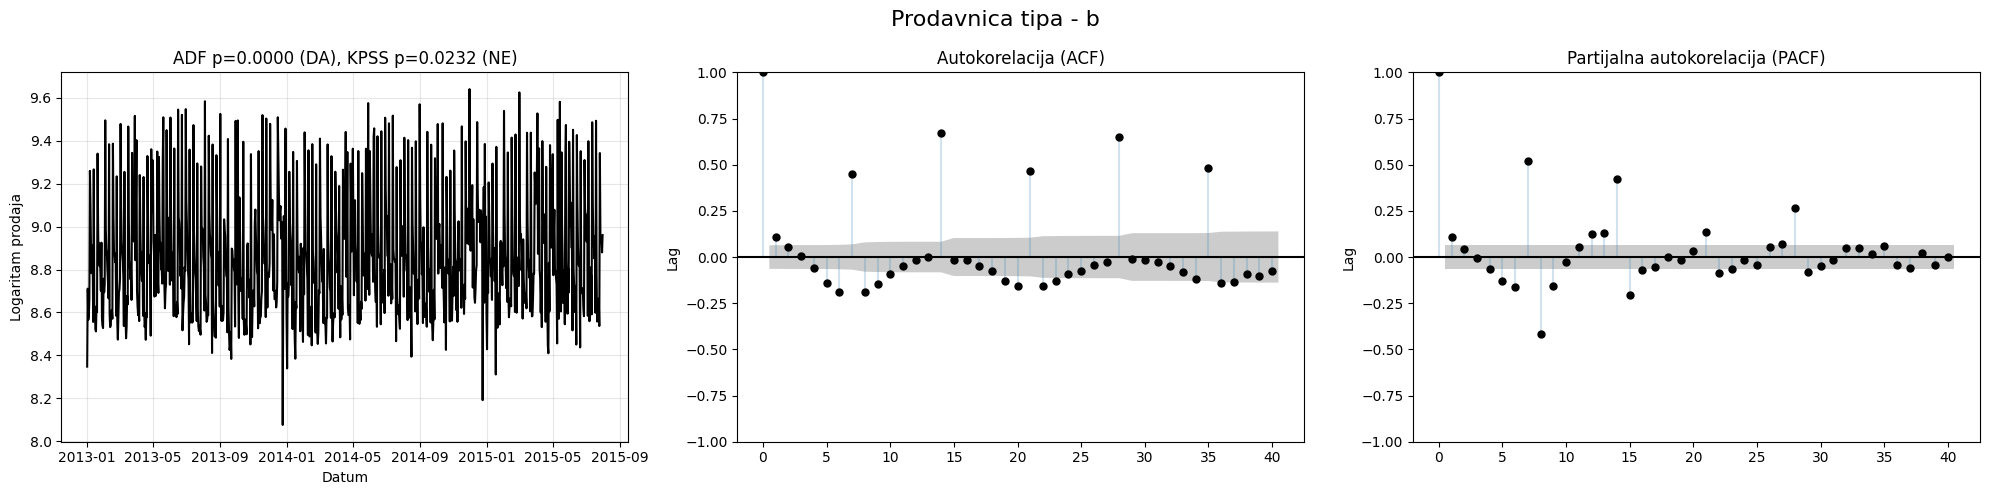

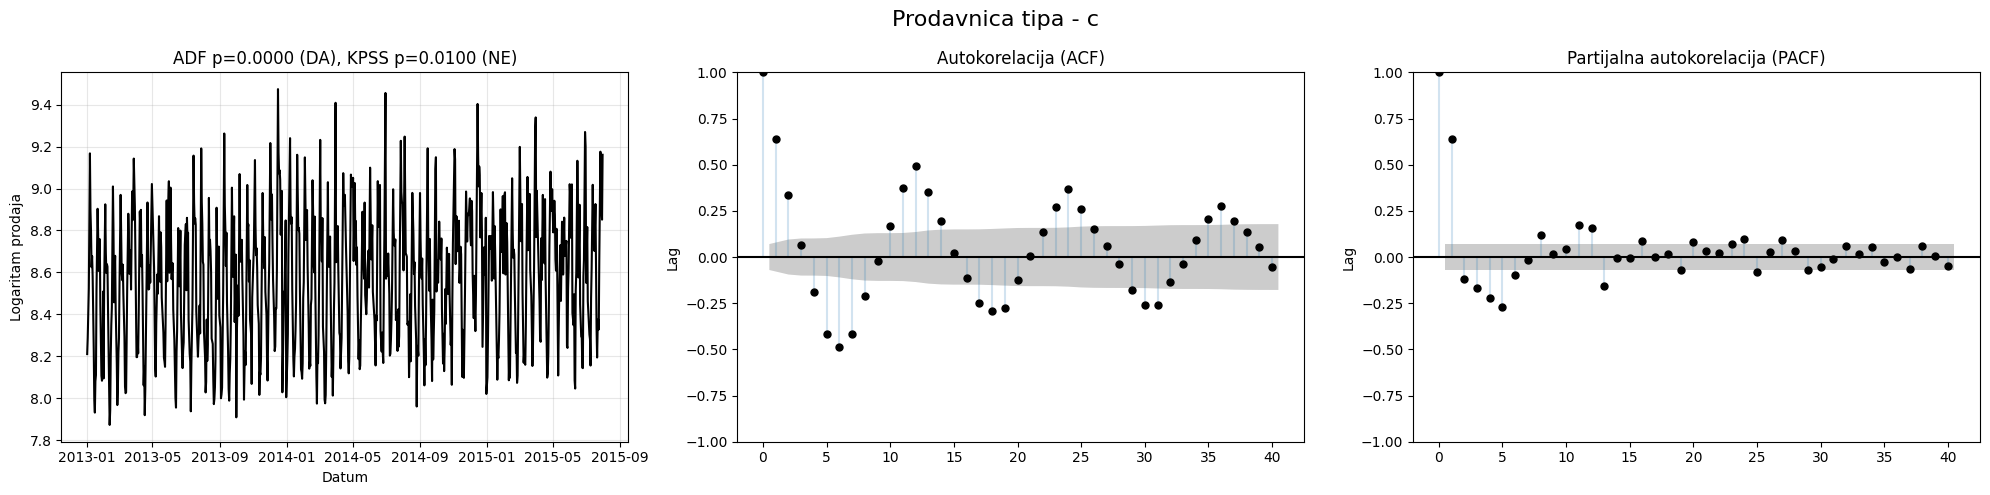

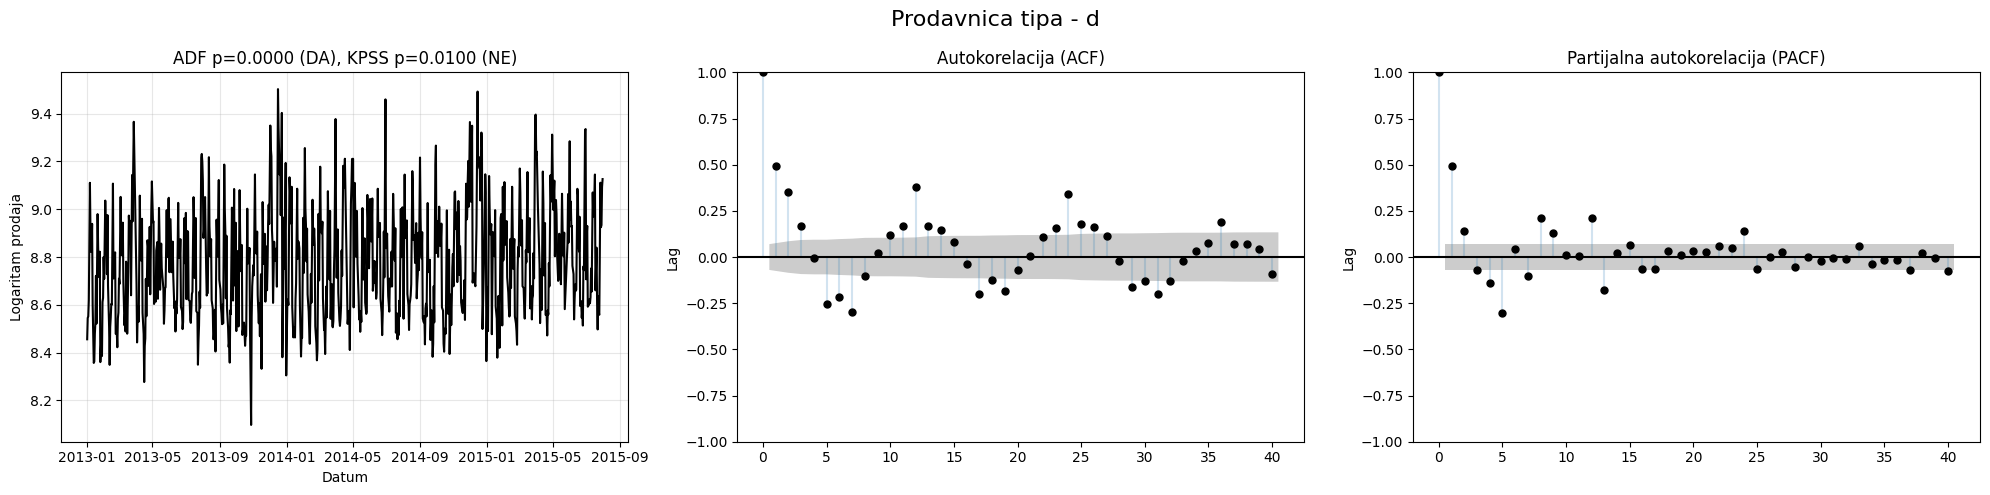

In [19]:
def plot_stationarity_acf_pacf(store_id, df):
    store_df = df[df['Store'] == store_id].sort_values('Date')
    ts = np.log1p(store_df['Sales'])
    
    store_type = store_df['StoreType'].iloc[0]

    adf_result = adfuller(ts)
    adf_p = adf_result[1]
    adf_stationary = "DA" if adf_p < 0.05 else "NE"

    kpss_result = kpss(ts, regression='c', nlags='auto')
    kpss_p = kpss_result[1]
    kpss_stationary = "DA" if kpss_p > 0.05 else "NE"

    fig, axes = plt.subplots(1, 3, figsize=(20,5))

    # Vremenska serija
    axes[0].plot(store_df['Date'], ts, color='black')
    axes[0].set_title(f'ADF p={adf_p:.4f} ({adf_stationary}), KPSS p={kpss_p:.4f} ({kpss_stationary})')
    axes[0].set_xlabel('Datum')
    axes[0].set_ylabel('Logaritam prodaja')
    axes[0].grid(alpha=0.3)

    # ACF
    acf_fig = plot_acf(ts, ax=axes[1], lags=40)
    for line in axes[1].lines:
        line.set_color('black')
    for poly in axes[1].collections:
        poly.set_facecolor('black')
        poly.set_alpha(0.2)
    axes[1].set_title('Autokorelacija (ACF)')
    axes[1].set_ylabel('Lag')

    # PACF
    pacf_fig = plot_pacf(ts, ax=axes[2], lags=40)
    for line in axes[2].lines:
        line.set_color('black')
    for poly in axes[2].collections:
        poly.set_facecolor('black')
        poly.set_alpha(0.2)
    axes[2].set_title('Partijalna autokorelacija (PACF)')
    axes[2].set_ylabel('Lag')

    fig.suptitle(f'Prodavnica tipa - {store_type}', fontsize=16)
    plt.tight_layout()
    plt.savefig("latex-izvestaj\grafici\store_" + store_type, dpi=75)
    plt.show()

# Primer poziva
for store_id in [8, 85, 21, 15]:
    plot_stationarity_acf_pacf(store_id, data)


### Korelacija sa osnovnim parametrima

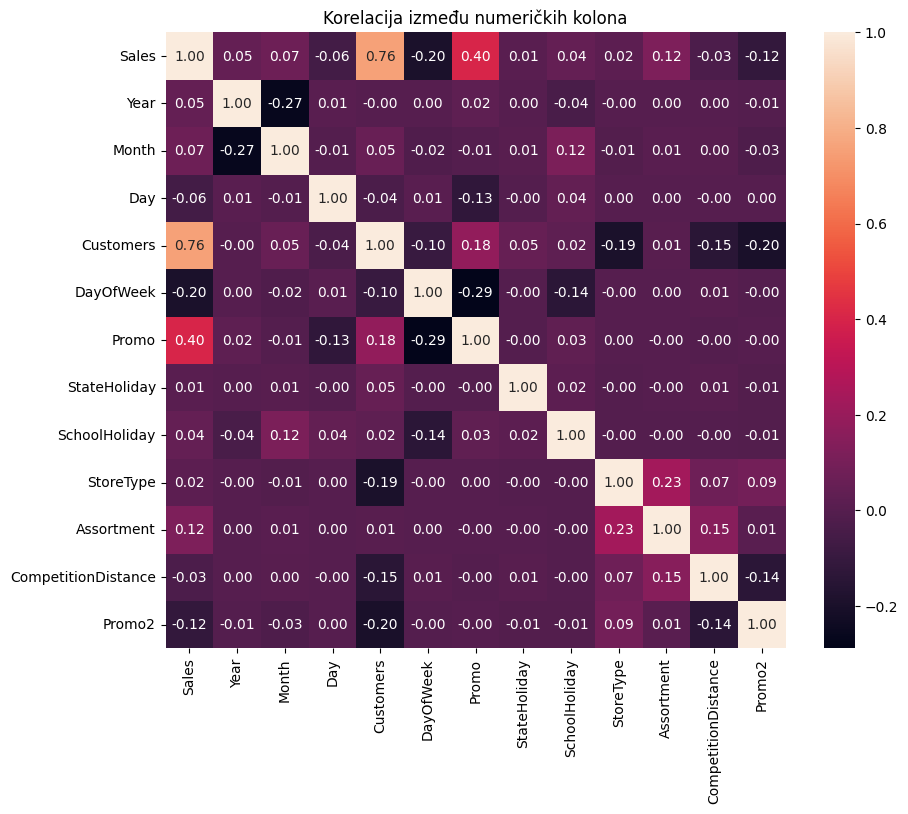

In [33]:
corr_cols = ['Sales',
             'Year', 'Month', 'Day', 'Customers',
             'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
             'StoreType', 'Assortment', 'CompetitionDistance', 'Promo2',
             ]

cat_cols = data.select_dtypes(include='object').columns[:3]
mappings = {'0':0, 'a':1, 'b':2, 'c':3, 'd':4}
for col in cat_cols:
    data[col] = data[col].map(mappings)
    
corr_df = data[corr_cols]
corr_df['Sales'] = np.log1p(corr_df.Sales)
plt.figure(figsize=(10,8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f")
plt.title('Korelacija između numeričkih kolona')
plt.savefig('latex-izvestaj/grafici/correlation_original.png', dpi=75)
plt.show()


### Outlier

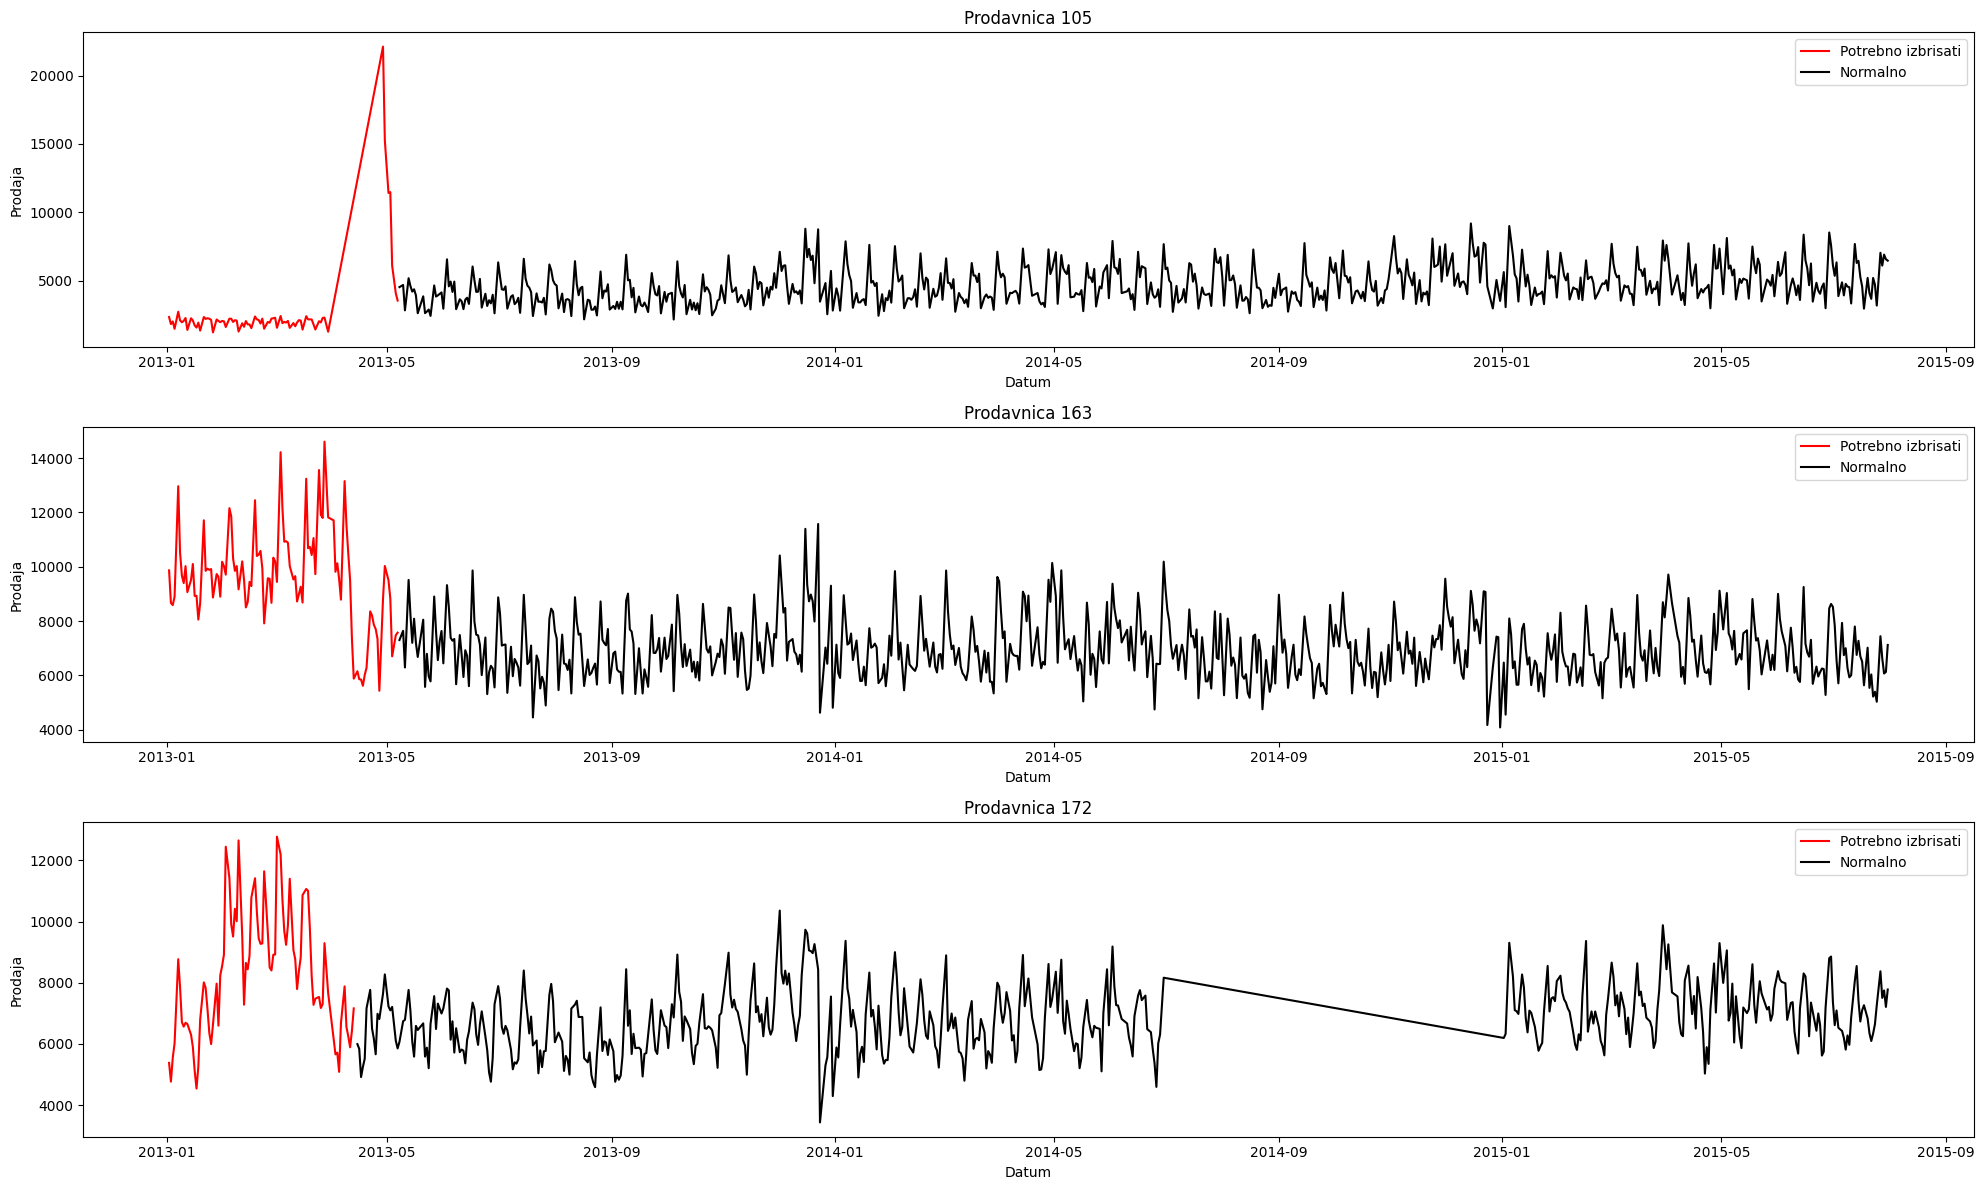

In [20]:
store_dates_to_remove = {105: '2013-05-08', 163: '2013-05-08', 172: '2013-04-15', 364: '2013-05-31', 378: '2014-01-17', 523: '2014-01-17', 
                         589: '2013-05-31', 663: '2014-01-17', 676: '2013-04-15', 681: '2013-05-31', 700: '2013-07-05', 708: '2013-05-08', 
                         709: '2015-02-03', 730: '2014-01-17', 764: '2013-05-08', 837: '2014-03-28', 845: '2013-05-08', 861: '2013-05-08', 
                         882: '2013-05-08', 969: '2013-04-15', 986: '2013-05-08', 192: '2015-01-11', 263: '2015-01-11', 500: '2015-01-11', 
                         797: '2015-01-11', 815: '2015-01-11', 825: '2015-01-11'}

data['Delete'] = False 

for key, value in store_dates_to_remove.items():
    data.loc[(data['Store'] == key) & (data['Date'] < value), 'Delete'] = True

list_stores_to_check = [105, 163, 172]

plt.rcParams["figure.figsize"] = [20, len(list_stores_to_check)*4]

i = 1
for stores in list_stores_to_check:

    X1 = data.loc[(data['Store'] == stores) & (data['Delete'] == True)]
    y1 = X1['Sales']

    X2 = data.loc[(data['Store'] == stores) & (data['Delete'] == False)]
    y2 = X2['Sales']

    plt.subplot(len(list_stores_to_check), 1, i)
    plt.plot(X1['Date'], y1, 'r-', label='Potrebno izbrisati')
    plt.plot(X2['Date'], y2, '-', color='black', label='Normalno')
    plt.title(f"Prodavnica {stores}")
    plt.ylabel('Prodaja')
    plt.xlabel('Datum')
    plt.legend()
    i += 1

plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\outlier_27stores.png', dpi=75)
plt.show()

data = data[data.Delete == 0].drop(columns = ['Delete'])

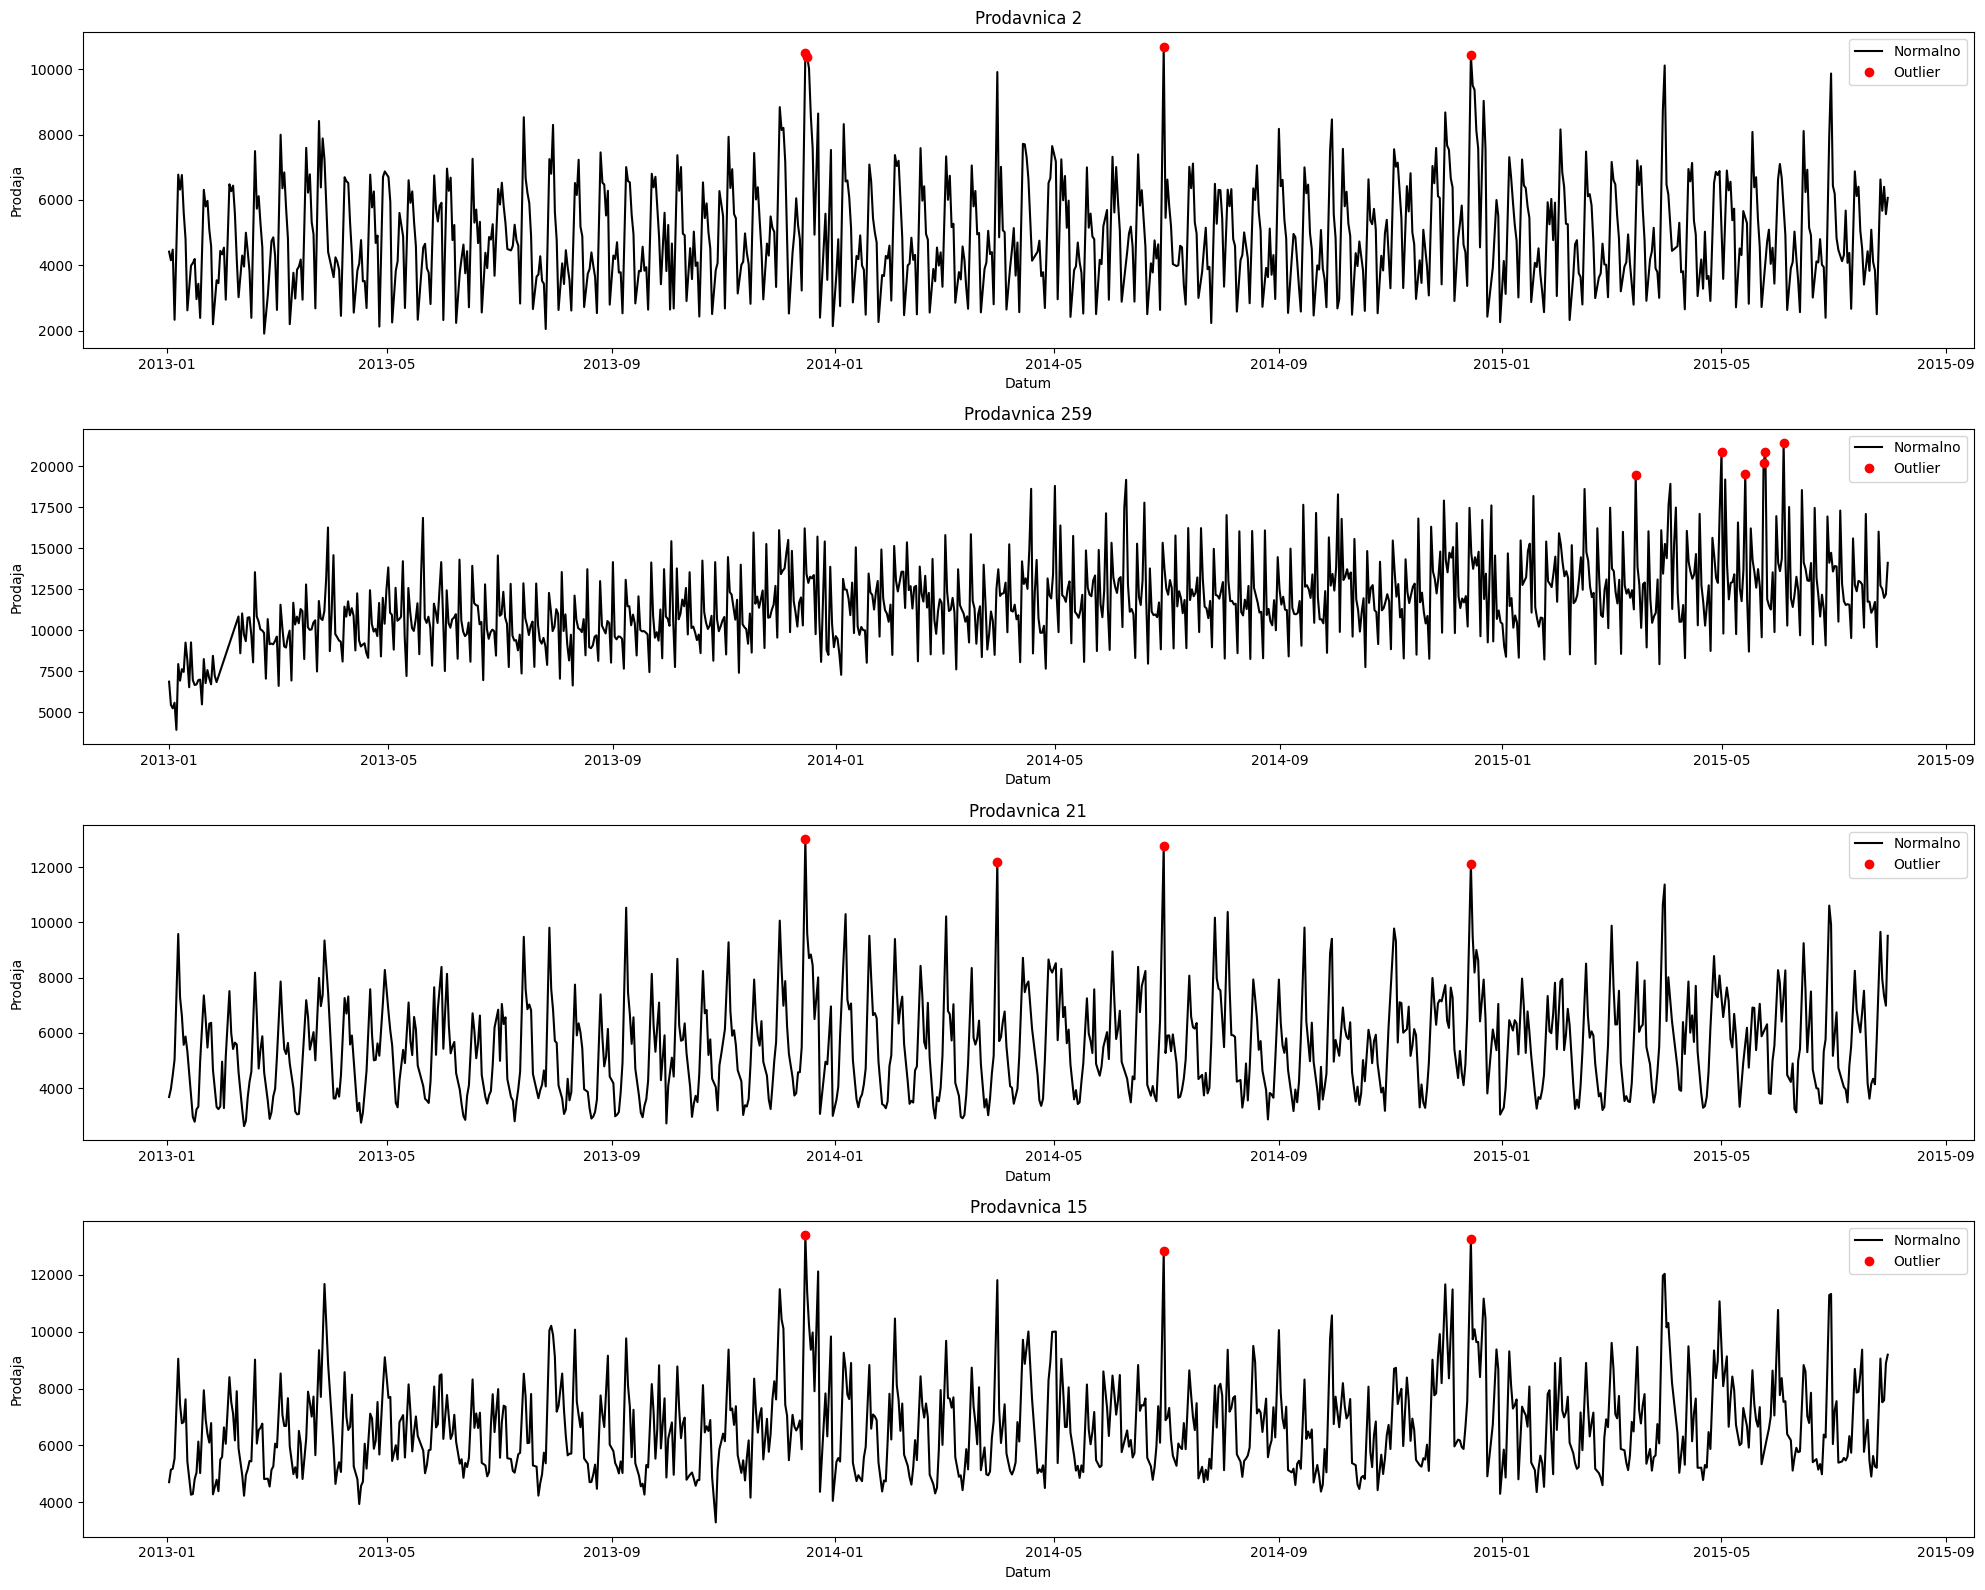

In [21]:
def mad_outlier(points, thresh=3.5):
    points = np.array(points)
    median = np.median(points)
    diff = np.abs(points - median)
    med_abs_deviation = np.median(diff)
    
    # Izbegni deljenje nulom
    if med_abs_deviation == 0:
        return np.zeros_like(points, dtype=bool)
    
    modified_z_score = 0.6745 * diff / med_abs_deviation
    return modified_z_score > thresh

# Primena po prodavnicama
data['Outlier'] = False
for i in data.Store.unique():
    data.loc[data['Store'] == i, 'Outlier'] = mad_outlier(data.loc[data['Store'] == i, 'Sales'])


list_stores_to_check = [2, 259, 21, 15]

plt.rcParams["figure.figsize"] = [20, len(list_stores_to_check)*4]

i = 1
for stores in list_stores_to_check:

    X1 = data.loc[(data['Store'] == stores) & (data['Outlier'] == True)]
    y1 = X1['Sales']

    X2 = data.loc[(data['Store'] == stores)]
    y2 = X2['Sales']

    plt.subplot(len(list_stores_to_check), 1, i)
    
    plt.plot(X2['Date'], y2, '-', color='black', label='Normalno')
    plt.plot(X1['Date'], y1, 'ro', label='Outlier')
    plt.title(f"Prodavnica {stores}")
    plt.ylabel('Prodaja')
    plt.xlabel('Datum')
    plt.legend()
    i += 1

plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\extreme_outliers.png', dpi=75)
plt.show()

## Feature engineering

In [ ]:
# ==========================
# Učitavanje podataka
# ==========================
store = pd.read_csv("data/store.csv")
data = pd.read_csv("data/train.csv", parse_dates=['Date'], dtype={'StateHoliday': 'str'})
test = pd.read_csv("data/test.csv", parse_dates=['Date'], dtype={'StateHoliday': 'str'})

# ==========================
# Popunjavanje nedostajućih vrednosti
# ==========================
store['CompetitionDistance'] = store['CompetitionDistance'].fillna(store['CompetitionDistance'].median())
store['CompetitionDistance'] = np.log1p(store['CompetitionDistance'])
store['CompetitionOpenSinceMonth'] = store['CompetitionOpenSinceMonth'].fillna(0)
store['CompetitionOpenSinceYear'] = store['CompetitionOpenSinceYear'].fillna(2025)

# ==========================
# Spajanje train i test podataka
# ==========================
data = pd.concat([data.assign(Train=1), test.assign(Train=0)])
data = pd.merge(data, store, on='Store', how='left')

# ==========================
# Kodiranje kategorijskih promenljivih
# ==========================
cat_cols = data.select_dtypes(include='object').columns[:3]
mappings = {'0':0, 'a':1, 'b':2, 'c':3, 'd':4}
for col in cat_cols:
    data[col] = data[col].map(mappings)

# ==========================
# Ekstrakcija vremenskih karakteristika
# ==========================
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day
data['WeekOfYear'] = data['Date'].dt.isocalendar().week

# ==========================
# Featuri vezani za konkurenciju i promocije
# ==========================
data['CompetitionOpenSince'] = (
        ((data['Year'] - data['CompetitionOpenSinceYear']) * 12) +
        (data['Month'] - data['CompetitionOpenSinceMonth'])
    ).clip(lower=0).fillna(0).astype(int)

data['PromoOpenSince'] = (
        ((data['Year'] - data['Promo2SinceYear']) * 52) +
        (data['WeekOfYear'] - data['Promo2SinceWeek'])
    ).clip(lower=0).fillna(0).astype(int)

data['isPromo2'] = data.apply(
        lambda row: row['Date'].strftime('%b') in str(row['PromoInterval']),
        axis=1).astype(int)

# ==========================
# Feature-i vezani za praznike
# ==========================
data['IsHoliday'] = (data['StateHoliday'] != 0).astype(int)
data = data.sort_values(['Store', 'Year', 'WeekOfYear'])

data['HolidayThisWeek'] = data.groupby(['Store','Year','WeekOfYear'])['IsHoliday'].transform('max')
data['HolidayLastWeek'] = data.groupby('Store')['HolidayThisWeek'].shift(1).fillna(0).astype(int)
data['HolidayNextWeek'] = data.groupby('Store')['HolidayThisWeek'].shift(-1).fillna(0).astype(int)

# ==========================
# Broj uzastopnih zatvorenih dana
# ==========================
def days_since_prev_open(df):
    last_open_date = None
    result = []
    for d, o in zip(df['Date'], df['Open']):
        if last_open_date is None:
            # ako još nije bilo otvorenog dana
            result.append(np.nan)
        else:
            result.append((d - last_open_date).days)
        if o == 1:
            # svaki otvoreni dan ažurira last_open_date
            last_open_date = d
    return pd.Series(result, index=df.index)

data = data.sort_values(['Store', 'Date'])
data['ClosureFeat'] = data.groupby('Store', group_keys=False).apply(days_since_prev_open)
data['ClosureFeat'] = data['ClosureFeat'].fillna(1) - 1

# ==========================
# Lista feature-a za model
# ==========================
features = [
    'Store','DayOfWeek','Promo','StateHoliday','SchoolHoliday','StoreType','Assortment',
    'CompetitionDistance','CompetitionOpenSinceMonth','Promo2',
    'CompetitionOpenSinceYear',
    'Year','Month','Day','WeekOfYear',
    'CompetitionOpenSince','PromoOpenSince','isPromo2',
    'HolidayThisWeek','HolidayLastWeek','HolidayNextWeek',
    'ClosureFeat'
]

# ==========================
# Uklanjanje problematičnih datuma po prodavnici
# ==========================
store_dates_to_remove = {
    105: '2013-05-08', 163: '2013-05-08', 172: '2013-04-15', 364: '2013-05-31', 
    378: '2014-01-17', 523: '2014-01-17', 589: '2013-05-31', 663: '2014-01-17', 
    676: '2013-04-15', 681: '2013-05-31', 700: '2013-07-05', 708: '2013-05-08', 
    709: '2015-02-03', 730: '2014-01-17', 764: '2013-05-08', 837: '2014-03-28', 
    845: '2013-05-08', 861: '2013-05-08', 882: '2013-05-08', 969: '2013-04-15', 
    986: '2013-05-08', 192: '2015-01-11', 263: '2015-01-11', 500: '2015-01-11', 
    797: '2015-01-11', 815: '2015-01-11', 825: '2015-01-11'
}

data['Delete'] = False 
for key, value in store_dates_to_remove.items():
    data.loc[(data['Store'] == key) & (data['Date'] < value), 'Delete'] = True
data = data[data.Delete == 0].drop(columns=['Delete'])

# ==========================
# Razdvajanje train i test podataka
# ==========================
test = data[data.Train == 0]
data = data[data.Train == 1]

# ==========================
# Filtriranje prodavnica sa nenultom prodajom
# ==========================
data = data[(data['Open'] == 1) & (data['Sales'] > 0)]

# ==========================
# Detekcija outliera po prodavnicama
# ==========================
def mad_outlier(points, thresh=3.5):
    points = np.array(points)
    median = np.median(points)
    diff = np.abs(points - median)
    med_abs_deviation = np.median(diff)
    
    if med_abs_deviation == 0:
        return np.zeros_like(points, dtype=bool)
    
    modified_z_score = 0.6745 * diff / med_abs_deviation
    return modified_z_score > thresh

data['Outlier'] = False
for store_id in data.Store.unique():
    data.loc[data['Store'] == store_id, 'Outlier'] = mad_outlier(data.loc[data['Store'] == store_id, 'Sales'])


### Feature engineering - za linearnu regresiju

In [6]:
# Lista feature-a za linearnu regresiju 
features_linreg = []

# Trend: broj dana od početka skupa podataka
data['days_since_start'] = (data['Date'] - data['Date'].min()).dt.days
data['log_days'] = np.log1p(data['days_since_start'])

test['days_since_start'] = (test['Date'] - data['Date'].min()).dt.days
test['log_days'] = np.log1p(test['days_since_start'])

features_linreg += ['days_since_start', 'log_days']

# Dodavanje Furijeovih redova
def add_fourier(df, col, period, order=3):
    global features_linreg
    for k in range(1, order + 1):
        sin_col = f"{col}_sin_{k}"
        cos_col = f"{col}_cos_{k}"
        df[sin_col] = np.sin(2 * np.pi * k * df[col] / period)
        df[cos_col] = np.cos(2 * np.pi * k * df[col] / period)
        features_linreg += [sin_col, cos_col]

# Za trening skup
add_fourier(data, 'DayOfWeek', 7, order=3)
add_fourier(data, 'Month', 12, order=3)
add_fourier(data, 'WeekOfYear', 52, order=3)
add_fourier(data, 'days_since_start', 365, order=5)

# Za test skup
add_fourier(test, 'DayOfWeek', 7, order=3)
add_fourier(test, 'Month', 12, order=3)
add_fourier(test, 'WeekOfYear', 52, order=3)
add_fourier(test, 'days_since_start', 365, order=5)

features_linreg = list(set(features_linreg))


## Predikcija

### Loss function

In [9]:
def ToWeight(y):
    w = np.zeros_like(y, dtype=float)
    w[y != 0] = 1. / (y[y != 0] ** 2)
    return w

def rmspe(yhat, y):
    w = ToWeight(y)
    return np.sqrt(np.mean(w * (y - yhat) ** 2))

def rmspe_xg(yhat, y):
    y = np.exp(y.get_label()) - 1
    yhat = np.exp(yhat) - 1
    return "rmspe", rmspe(yhat, y)


### Pronalazenje optimalnih parametara i izmena outliera

In [5]:
data = data.sort_values(by='Date')

# Priprema skupa za treniranje (bez outlier-a)
X_train = data.loc[data['Outlier'] == False, features]
y_train = np.log1p(data.loc[data['Outlier'] == False, 'Sales'])

# Podela na train i validacioni skup
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42
)

dtrain = xgb.DMatrix(X_tr, label=y_tr)
dvalid = xgb.DMatrix(X_val, label=y_val)
"""
# Optuna optimizacije
def objective(trial):
    params = {
        'objective': 'reg:squarederror',
        'tree_method': 'hist', # 'gpu_hist'
        'max_depth': trial.suggest_int('max_depth', 8, 16),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 5),
        'subsample': 0.7,  
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.7),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 1),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 1),
        'random_state': 42
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=20000,
        evals=[(dvalid, 'val')],
        early_stopping_rounds=250,
        verbose_eval=False
    )

    y_pred_val = np.expm1(model.predict(dvalid))
    y_val_orig = np.expm1(y_val)

    return rmspe(y_val_orig, y_pred_val)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50)

print("Najbolji parametri:", study.best_params)
print("Najbolji RMSPE:", study.best_value)

# Finalni trening na celom skupu bez outlier-a
best_params = study.best_params
"""

best_params = {
        'objective': 'reg:squarederror',
        'tree_method': 'hist',
        'max_depth': 14,
        'min_child_weight': 1,
        'subsample': 0.7,
        'colsample_bytree': 0.6,
        'eta': 0.06,
        'gamma': 0.2,
        'reg_alpha': 0.62,
        'reg_lambda': 0.5,
        'random_state': 42
    }


model_clean = xgb.train(
    best_params,
    dtrain,
    num_boost_round=20000,
    evals=[(dvalid, 'val')],
    early_stopping_rounds=250,
    verbose_eval=False
)

# Predikcija za outlier-e i zamena vrednosti
X_out = data.loc[data['Outlier'] == True, features]
dout = xgb.DMatrix(X_out)
data.loc[data['Outlier'] == True, "Sales"] = np.expm1(model_clean.predict(dout))

### Dodatni feature engineering - statistika

In [6]:
def agg_stats_by_time(df, window_days):
    """
    Računanje proseka logaritamkse transformacije 'Sales' u zadatom vremenskom prozoru
    unazad od trenutnog datuma.
    """
    df = df.sort_index()
    results = []

    for current_date in df.index:
        start_date = current_date - pd.Timedelta(days=window_days)
        window_data = df.loc[(df.index > start_date) & (df.index < current_date), 'Sales'].dropna()
        mean_ = np.log1p(window_data).mean()
        results.append([mean_])

    cols = [f'mean_{window_days}D']
    return pd.DataFrame(results, index=df.index, columns=cols)

df = pd.concat([data.assign(train=1), test.assign(train=0)])
df = df.sort_values(['Store', 'Date']).set_index('Date')

# Definisani vremenski prozori
windows = [90, 365]

# Vremenske karakteristike po prodavnici
features_main = []
for w in windows:
    print(f"Calculating MAIN time-based stats for window {w} days...")
    feat = df.groupby('Store').progress_apply(lambda g: agg_stats_by_time(g, w))
    features_main.append(feat)

features_main = pd.concat(features_main, axis=1).reset_index()

# Uslovne vremenske karakteristike
features_cond = []
for w in windows:
    print(f"Calculating CONDITIONAL time-based stats for window {w} days...")
    feat = (
        df.groupby(['Store', 'Promo', 'StateHoliday'])
          .progress_apply(lambda g: agg_stats_by_time(g, w))
          .add_prefix("cond_")
    )
    features_cond.append(feat)

features_cond = pd.concat(features_cond, axis=1).reset_index()
features_cond = features_cond.drop(columns=['Promo', 'StateHoliday'])

df_features = pd.merge(features_main, features_cond, how='inner', on=['Date', 'Store'])
df = pd.merge(df, df_features, how='left', on=['Date', 'Store'])

data = df[df.train == 1].copy()
test = df[df.train == 0].copy()

# Popunjavanje nedostajućih vrednosti
features.extend(['cond_mean_90D', 'cond_mean_365D'])

data['mean_90D'] = data['mean_90D'].fillna(data['mean_365D'])
data['cond_mean_90D'] = data['cond_mean_90D'].fillna(data['mean_90D'])
data['cond_mean_365D'] = data['cond_mean_365D'].fillna(data['mean_365D'])
test['cond_mean_90D'] = test['cond_mean_90D'].fillna(test['mean_90D'])
test['cond_mean_365D'] = test['cond_mean_365D'].fillna(test['mean_365D'])

data = data[~data['mean_90D'].isna()]

# Računanje agregata po prodavnici
store_sales = data.groupby('Store')['Sales'].sum()
store_customers = data.groupby('Store')['Customers'].sum()
store_opens = data.groupby('Store')['Sales'].count()

sales_per_day = store_sales / store_opens
customer_per_day = store_customers / store_opens
sales_per_customer = store_sales / store_customers

for df_target in [data, test]:
    df_target = pd.merge(df_target, sales_per_day.reset_index(name='SalesPerDay'), how='left', on='Store')
    df_target = pd.merge(df_target, customer_per_day.reset_index(name='CustomersPerDay'), how='left', on='Store')
    df_target = pd.merge(df_target, sales_per_customer.reset_index(name='SalesPerCustomers'), how='left', on='Store')

# Ponovo dodaj u glavne varijable
data = pd.merge(data, sales_per_day.reset_index(name='SalesPerDay'), how='left', on='Store')
data = pd.merge(data, customer_per_day.reset_index(name='CustomersPerDay'), how='left', on='Store')
data = pd.merge(data, sales_per_customer.reset_index(name='SalesPerCustomers'), how='left', on='Store')

test = pd.merge(test, sales_per_day.reset_index(name='SalesPerDay'), how='left', on='Store')
test = pd.merge(test, customer_per_day.reset_index(name='CustomersPerDay'), how='left', on='Store')
test = pd.merge(test, sales_per_customer.reset_index(name='SalesPerCustomers'), how='left', on='Store')


Calculating MAIN time-based stats for window 90 days...


100%|██████████| 1115/1115 [13:16<00:00,  1.40it/s]


Calculating MAIN time-based stats for window 365 days...


100%|██████████| 1115/1115 [12:20<00:00,  1.51it/s]


Calculating CONDITIONAL time-based stats for window 90 days...


100%|██████████| 2668/2668 [12:41<00:00,  3.50it/s]


Calculating CONDITIONAL time-based stats for window 365 days...


100%|██████████| 2668/2668 [12:45<00:00,  3.49it/s]


### Korelacija između kolona

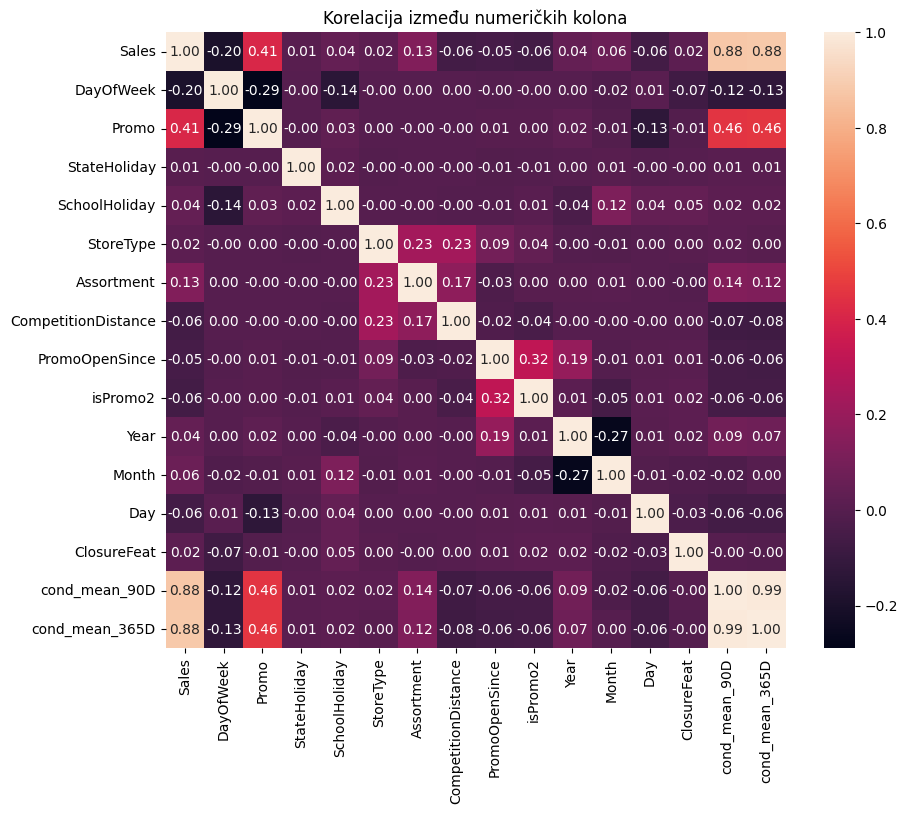

In [ ]:
corr_cols = ['Sales','DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
             'StoreType', 'Assortment', 'CompetitionDistance', 'PromoOpenSince', 'isPromo2',
             'Year', 'Month', 'Day', 
             'ClosureFeat',
            'cond_mean_90D', 'cond_mean_365D']
corr_df = data[corr_cols]
corr_df['Sales'] = np.log1p(corr_df.Sales)
plt.figure(figsize=(10,8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f")
plt.title('Korelacija između numeričkih kolona')
plt.savefig('latex-izvestaj/grafici/correlation_engineered.png')
plt.show()


### Konstantan izlaz

In [ ]:
df = data.copy()

# Globalni prosek prodaje za iste mesece i dane kao u test setu
global_mean = df[
    (df['Month'].isin(test['Month'])) &
    (df['Day'].isin(test['Day']))
]['Sales'].mean()

# Prosek po prodavnici
for store in test['Store'].unique():
    # Prosek za konkretan store
    mean_store = df[
        (df['Store'] == store) &
        (df['Month'].isin(test['Month'])) &
        (df['Day'].isin(test['Day']))
    ]['Sales'].mean()

    # Ako store nema istoriju uzima se globalni prosek
    if pd.isna(mean_store):
        mean_store = global_mean

    test.loc[test['Store'] == store, 'Sales'] = mean_store

# Kreiranje submission fajla
submission = pd.DataFrame({
    "Id": test["Id"],
    "Sales": test["Sales"]
})

submission = submission.sort_values(by='Id').reset_index(drop=True)
submission['Id'] = submission['Id'].astype(int)
submission.to_csv("result/submission_const.csv", index=False)

### Linearna regresija

#### Globalno

In [ ]:
df = data.copy()
test_linreg = test.copy()

# Kombinacija feature-a
features_lin_reg = features_linreg.copy()
features_lin_reg.extend(features)
features_lin_reg.extend(['SalesPerDay', 'CustomersPerDay', 'SalesPerCustomers'])
features_lin_reg.remove('Store')

X = df[features_lin_reg].values
X_test = test_linreg[features_lin_reg].values
y = np.log1p(df['Sales'].values).reshape(-1, 1)  # log-transformacija

# Skaliranje
X_scaler = MinMaxScaler()
X_scaled = X_scaler.fit_transform(X)
X_test_scaled = X_scaler.transform(X_test)

y_scaler = MinMaxScaler()
y_scaled = y_scaler.fit_transform(y)

# Sortiranje po Store i Date za validaciju
df_sorted = df.sort_values(['Date', 'Store']).reset_index(drop=True)
X_sorted = X_scaled[df_sorted.index]
y_sorted = y_scaled[df_sorted.index]

# Poslednjih 10% za validaciju
val_size = int(len(X_sorted) * 0.1)
X_train, X_val = X_sorted[:-val_size], X_sorted[-val_size:]
y_train, y_val = y_sorted[:-val_size], y_sorted[-val_size:]

# Pronalazak najboljeg alpha za Ridge regresiju
alphas = np.logspace(1, 2, 40)
alpha_scores = {}

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    y_pred_scaled = model.predict(X_val)
    y_pred = np.expm1(y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1))).flatten()
    y_val_orig = np.expm1(y_scaler.inverse_transform(y_val))

    score = rmspe(y_val_orig.reshape(-1, 1), y_pred.reshape(-1, 1))
    alpha_scores[alpha] = score
    print(f"Alpha={alpha:.5f} | RMSPE={score:.5f}")

best_alpha = min(alpha_scores, key=alpha_scores.get)
print(f"\nNajbolji alpha: {best_alpha} | RMSPE={alpha_scores[best_alpha]:.5f}")

# Treniranje finalnog modela
best_model = Ridge(alpha=best_alpha)
best_model.fit(X_scaled, y_scaled)

# Predikcija na test skupu
y_test_scaled = best_model.predict(X_test_scaled)
y_test_pred = np.expm1(y_scaler.inverse_transform(y_test_scaled.reshape(-1, 1))).flatten()

# Kreiranje submission fajla
submission = pd.DataFrame({
    "Id": test_linreg["Id"],
    "Sales": 0.975 * y_test_pred  
})

submission = submission.sort_values(by='Id').reset_index(drop=True)
submission['Id'] = submission['Id'].astype(int)
submission.to_csv("result/submission_lin_reg.csv", index=False)

Alpha=10.00000 | RMSPE=0.20408
Alpha=10.60818 | RMSPE=0.20407
Alpha=11.25336 | RMSPE=0.20407
Alpha=11.93777 | RMSPE=0.20406
Alpha=12.66380 | RMSPE=0.20406
Alpha=13.43399 | RMSPE=0.20406
Alpha=14.25103 | RMSPE=0.20405
Alpha=15.11775 | RMSPE=0.20405
Alpha=16.03719 | RMSPE=0.20404
Alpha=17.01254 | RMSPE=0.20404
Alpha=18.04722 | RMSPE=0.20403
Alpha=19.14482 | RMSPE=0.20402
Alpha=20.30918 | RMSPE=0.20402
Alpha=21.54435 | RMSPE=0.20401
Alpha=22.85464 | RMSPE=0.20401
Alpha=24.24462 | RMSPE=0.20400
Alpha=25.71914 | RMSPE=0.20400
Alpha=27.28333 | RMSPE=0.20399
Alpha=28.94266 | RMSPE=0.20398
Alpha=30.70291 | RMSPE=0.20398
Alpha=32.57021 | RMSPE=0.20397
Alpha=34.55107 | RMSPE=0.20397
Alpha=36.65241 | RMSPE=0.20396
Alpha=38.88155 | RMSPE=0.20395
Alpha=41.24626 | RMSPE=0.20395
Alpha=43.75479 | RMSPE=0.20394
Alpha=46.41589 | RMSPE=0.20394
Alpha=49.23883 | RMSPE=0.20393
Alpha=52.23345 | RMSPE=0.20393
Alpha=55.41020 | RMSPE=0.20392
Alpha=58.78016 | RMSPE=0.20392
Alpha=62.35507 | RMSPE=0.20392
Alpha=66

#### Lokalno

In [ ]:
df = data.copy()
test_linreg = test.copy()

# Kombinacija relevantnih feature-a
features_lin_reg = features_linreg.copy()
features_lin_reg.extend(features)
features_lin_reg.extend(['SalesPerDay', 'CustomersPerDay', 'SalesPerCustomers'])
if 'Store' in features_lin_reg:
    features_lin_reg.remove('Store')

# Ukloniti feature-e koji su konstantni po Store-u
constant_features = []
for f in features_lin_reg:
    grouped = df.groupby('Store')[f].nunique()
    if (grouped <= 1).all():
        constant_features.append(f)

features_ridge_base = [f for f in features_lin_reg if f not in constant_features]
print(f"Broj upotrebljenih feature-a: {len(features_ridge_base)}")

df['log_sales'] = np.log1p(df['Sales'])
store_best_alpha = {}

alphas = np.logspace(-1, 1, 20)  # kandidati za Ridge alpha

# Petlja po svakoj prodavnici
for store_id in df['Store'].unique():
    store_train = df.loc[df['Store'] == store_id].copy()
    store_test = test_linreg.loc[test_linreg['Store'] == store_id].copy()

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_store = scaler_X.fit_transform(store_train[features_ridge_base])
    y_store = scaler_y.fit_transform(store_train[['log_sales']])

    # Train/Val split 
    X_train, X_val, y_train, y_val = train_test_split(
        X_store, y_store, test_size=0.2, random_state=42, shuffle=False
    )

    # Pretraga optimalnog parametra
    best_alpha, best_score = None, float('inf')
    for alpha in alphas:
        model = Ridge(alpha=alpha)
        model.fit(X_train, y_train)
        y_pred_scaled = model.predict(X_val)
        y_pred = np.expm1(scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))).flatten()
        y_val_orig = np.expm1(scaler_y.inverse_transform(y_val))
        score = rmspe(y_val_orig.reshape(-1, 1), y_pred.reshape(-1, 1))
        if score < best_score:
            best_alpha, best_score = alpha, score

    store_best_alpha[store_id] = best_alpha

    model = Ridge(alpha=best_alpha)
    model.fit(X_store, y_store)

    # Predikcija za train skupu 
    preds_train = np.expm1(
        scaler_y.inverse_transform(model.predict(X_store).reshape(-1, 1))
    )
    df.loc[df['Store'] == store_id, 'Seasonality'] = preds_train

    # Predikcija za test skupu 
    if len(store_test) > 0:
        X_test_store = scaler_X.transform(store_test[features_ridge_base])
        preds_test = np.expm1(
            scaler_y.inverse_transform(model.predict(X_test_store).reshape(-1, 1))
        )
        test_linreg.loc[test_linreg['Store'] == store_id, 'Seasonality'] = preds_test

    if store_id % 50 == 1:
        print(f"Store {store_id}: best alpha={best_alpha:.3f}")

submission = test_linreg[['Id', 'Seasonality']].sort_values(by='Id')
submission = submission.rename(columns = {'Seasonality':'Sales'})
submission['Id'] = submission['Id'].astype(int)
submission.to_csv('result/submission_lin_reg.csv', index=False)

Broj upotrebljenih feature-a: 45
Store 1: best alpha=0.100
Store 51: best alpha=4.833
Store 101: best alpha=0.546
Store 151: best alpha=6.158
Store 201: best alpha=1.129
Store 251: best alpha=0.428
Store 301: best alpha=1.833
Store 351: best alpha=0.264
Store 401: best alpha=7.848
Store 451: best alpha=0.886
Store 501: best alpha=10.000
Store 551: best alpha=3.793
Store 601: best alpha=7.848
Store 651: best alpha=10.000
Store 701: best alpha=0.100
Store 751: best alpha=10.000
Store 801: best alpha=0.428
Store 851: best alpha=4.833
Store 901: best alpha=10.000
Store 951: best alpha=1.438
Store 1001: best alpha=0.886
Store 1051: best alpha=0.100
Store 1101: best alpha=3.793


#### Hibridno

In [ ]:
df = data.copy()
test_linreg = test.copy()

# Lista karakteristika
features_lin_reg = features + ['SalesPerDay', 'CustomersPerDay', 'SalesPerCustomers']

X = df[features_lin_reg].values
X_test = test_linreg[features_lin_reg].values

# Priprema i skaliranje
y = np.log1p(df['Sales'].values).reshape(-1, 1) - np.log1p(df['Seasonality'].values).reshape(-1, 1)
y_scaler = MinMaxScaler()
y_scaled = y_scaler.fit_transform(y)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

df_sorted = df.sort_values(['Date', 'Store']).reset_index(drop=True)

X_sorted = X_scaled[df_sorted.index]
y_sorted = y_scaled[df_sorted.index]

# Train/Val split 
val_size = int(len(X_sorted) * 0.1)

X_train, X_val = X_sorted[:-val_size], X_sorted[-val_size:]
y_train, y_val = y_sorted[:-val_size], y_sorted[-val_size:]

alphas = np.logspace(0, 4, 40)
alpha_scores = {}

# Pretraga optimalnog parametra
for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    y_pred_scaled = model.predict(X_val)
    y_pred = np.expm1(y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1))).flatten()
    y_val_orig = np.expm1(y_scaler.inverse_transform(y_val))

    score = np.sqrt(np.mean((y_val_orig.reshape(-1, 1) -  y_pred.reshape(-1, 1))**2))
    alpha_scores[alpha] = score
    print(f"Alpha={alpha:.5f} | RMSPE={score:.5f}")

best_alpha = min(alpha_scores, key=alpha_scores.get)
print(f"\nNajbolji alpha: {best_alpha} | RMSPE={alpha_scores[best_alpha]:.5f}")

# Treniranje finalnog modela 
best_model = Ridge(alpha=best_alpha)
best_model.fit(X_scaled, y_scaled)

# Predikcija na test skupu 
y_test_scaled = best_model.predict(X_test_scaled)
y_test_pred = np.expm1(y_scaler.inverse_transform(y_test_scaled.reshape(-1, 1)) + np.log1p(test['Seasonality']).values.reshape(-1,1)).flatten()

submission = pd.DataFrame({"Id": test_linreg["Id"], "Sales": 0.975*y_test_pred})
submission = submission.sort_values(by=['Id']).reset_index(drop=True)
submission['Id'] = submission['Id'].astype(int)
submission.to_csv("result/submission_lin_reg.csv", index=False)


### XGBoost regresija

#### Globalno

In [ ]:
features_xgb = features + ['SalesPerDay', 'CustomersPerDay', 'SalesPerCustomers']
X_data = data[features_xgb]
y_data = np.log1p(data['Sales'])

# Podela na trening i validacioni skup
X_train, X_valid, y_train, y_valid = train_test_split(
    X_data, y_data, test_size=0.1, random_state=42, stratify=X_data["Store"]
)

dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid)

# Definisanje XGBoost hiperparametara
xgb_params = {
        'objective': 'reg:squarederror',
        'tree_method': 'hist',
        'max_depth': 14,
        'min_child_weight': 3,
        'subsample': 0.6,
        'colsample_bytree': 0.7,
        'eta': 0.08,
        'gamma': 0,
        'reg_alpha': 0.2,
        'reg_lambda': 0.6,
        'random_state': 42
}

# Trening modela
model_xgb = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=20000,
    evals=[(dvalid, "validation")],
    custom_metric=rmspe_xg,             
    early_stopping_rounds=250,
    verbose_eval=250
)

# Predikcija na test skupu
dtest = xgb.DMatrix(test[features_xgb])
y_test_pred = np.expm1(model_xgb.predict(dtest))
y_test_pred *= 0.975 

# Kreiranje submission fajla
submission_xgb = pd.DataFrame({
    "Id": test["Id"],
    "Sales": y_test_pred
})

submission_xgb = submission_xgb.sort_values(by='Id').reset_index(drop=True)
submission_xgb['Id'] = submission_xgb['Id'].astype(int)
submission_xgb.to_csv("result/submission_xgboost.csv", index=False)


[0]	validation-rmse:0.39042	validation-rmspe:0.47158
[250]	validation-rmse:0.08560	validation-rmspe:0.09837
[500]	validation-rmse:0.08491	validation-rmspe:0.09749
[748]	validation-rmse:0.08520	validation-rmspe:0.09787


#### Hibridno

In [ ]:
features_xgb = features + ['SalesPerDay', 'CustomersPerDay', 'SalesPerCustomers']
#features_xgb.remove('Store')
X_full = data[features_xgb] 
y_full = np.log1p(data['Sales']) - np.log1p(data['Seasonality'])

X_tr_final, X_val_final, y_tr_final, y_val_final = train_test_split(
    X_full, y_full, test_size=0.1, random_state=42, stratify=X_full["Store"]
)

dtrain_full = xgb.DMatrix(X_tr_final, label=y_tr_final)
dvalid_full = xgb.DMatrix(X_val_final, label=y_val_final)
params = {
        'objective': 'reg:squarederror',
        'tree_method': 'hist',
        'max_depth': 14,
        'min_child_weight': 1,
        'subsample': 0.7,
        'colsample_bytree': 0.66,
        'eta': 0.043,
        'gamma': 0.0022,
        'reg_alpha': 0.41,
        'reg_lambda': 0.6,
        'random_state': 42
    }

# Trening sa early stopping-om i istim parametrima
model = xgb.train(
    params,
    dtrain_full,
    num_boost_round=20000,        
    evals=[(dvalid_full, "valid")],
    #feval=rmspe_xg,
    early_stopping_rounds=250,
    verbose_eval=250             
)

# Predikcija na test skupu i submission
dtest = xgb.DMatrix(test[features_xgb])
test_pred = np.expm1(model.predict(dtest) + np.log1p(test['Seasonality']))
test_pred = test_pred

submission = pd.DataFrame({
    "Id": test["Id"],
    "Sales": test_pred
})

submission = submission.sort_values(by=['Id'])
submission.reset_index(drop=True)
submission['Id'] = submission['Id'].astype(int)
submission.to_csv("result/submission_xgboost.csv", index=False)


[0]	valid-rmse:0.12315
[250]	valid-rmse:0.08237
[500]	valid-rmse:0.08168
[750]	valid-rmse:0.08158
[888]	valid-rmse:0.08161


### Primer predikcija

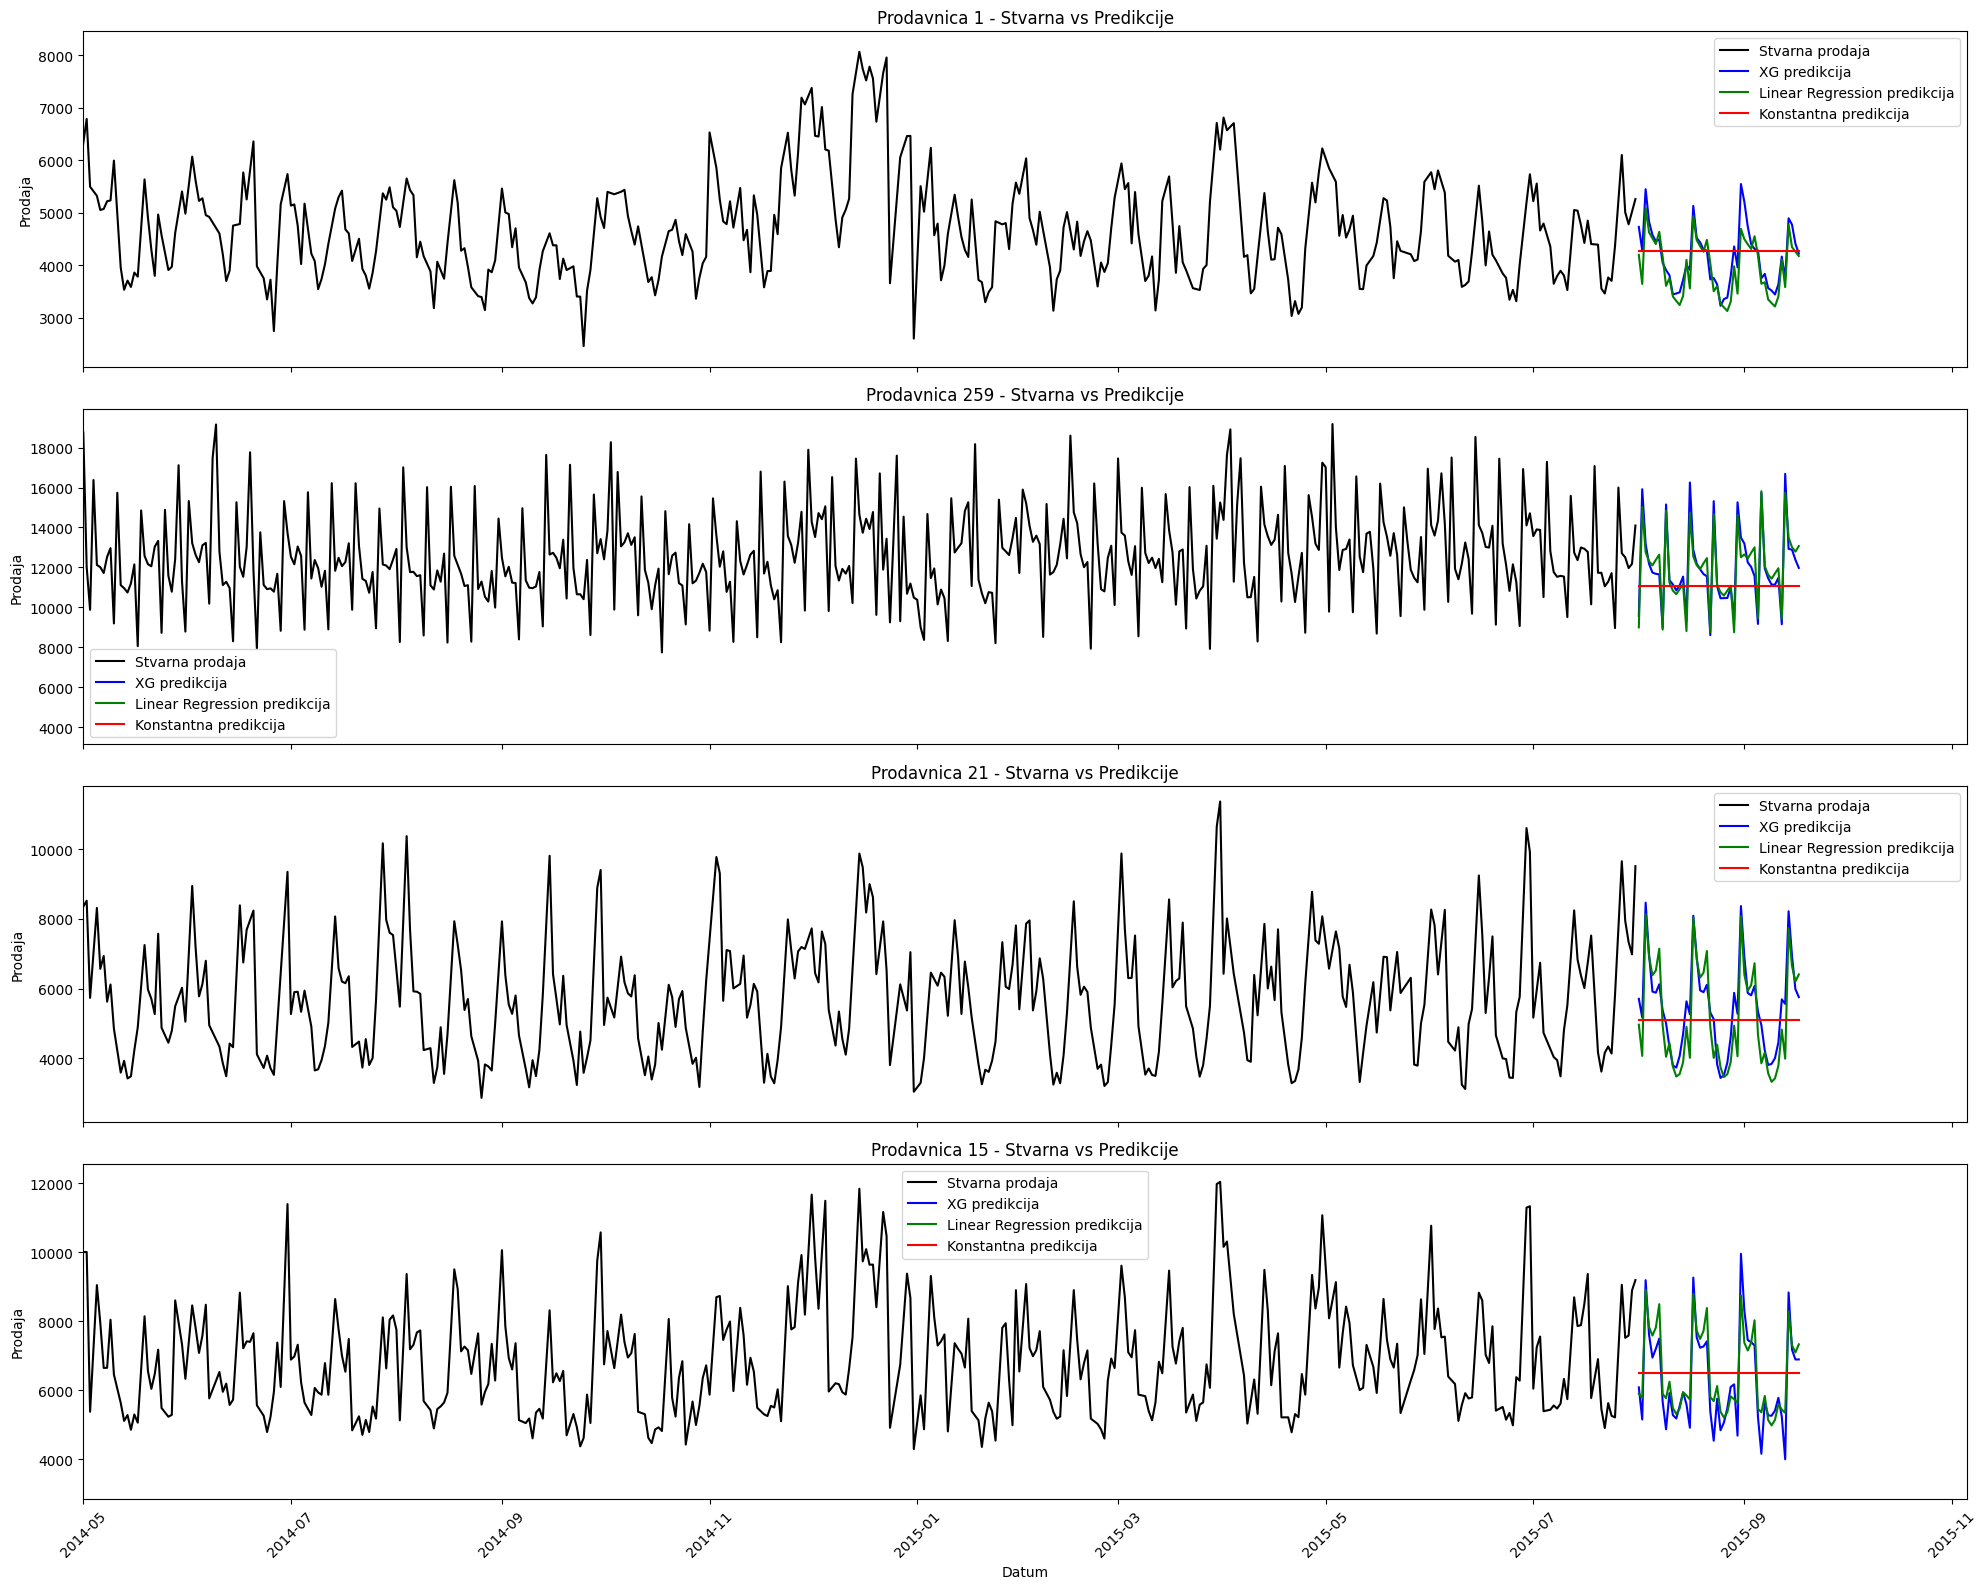

In [ ]:
train = pd.read_csv('data/train_with_seasonality.csv', parse_dates=['Date'])
test = pd.read_csv('data/test_with_seasonality.csv', parse_dates=['Date'])

xg = pd.read_csv('submission_xgboost.csv')
linreg = pd.read_csv('submission_lin_reg.csv')
const = pd.read_csv('submission_const.csv')

store_indices = [1, 259, 21, 15]

fig, axes = plt.subplots(len(store_indices), 1, figsize=(20, 4*len(store_indices)), sharex=True)

for ax, idx in zip(axes, store_indices):
    store_data = train[train['Store'] == idx]
    test_data = test.loc[test['Store'] == idx, ['Date', 'Id']]
    
    # Spajanje predikcija
    test_data = pd.merge(test_data, xg, on='Id')
    test_data.rename(columns={'Sales':'XG'}, inplace=True)
    test_data = pd.merge(test_data, linreg, on='Id')
    test_data.rename(columns={'Sales':'linreg'}, inplace=True)
    test_data = pd.merge(test_data, const, on='Id')
    test_data.rename(columns={'Sales':'const'}, inplace=True)
    
    # Plot stvarnih podataka
    ax.plot(store_data['Date'], store_data['Sales'], label='Stvarna prodaja', color='black')
    
    # Plot predikcija
    ax.plot(test_data['Date'], test_data['XG'], label='XG predikcija', color='blue')
    ax.plot(test_data['Date'], test_data['linreg'], label='Linear Regression predikcija', color='green')
    ax.plot(test_data['Date'], test_data['const'], label='Konstantna predikcija', color='red')
    
    ax.set_title(f'Prodavnica {idx} - Stvarna vs Predikcije')
    ax.set_ylabel('Prodaja')
    ax.legend()

axes[-1].set_xlabel('Datum')
plt.xlim(left=pd.Timestamp('2014-05-01'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('latex-izvestaj\grafici\prediction_final.png', dpi=75)
plt.show()
